# 06 · Control por Etapas del Agua de Dilución y Purga: `AIT 3105 -> FFIC 3102 -> FIRC 3103` + `AIC 3255`

Este cuaderno integra el análisis por etapas del subsistema de agua de dilución en **A3110** (Partes B1–B4 de los cuadernos 05) con la simulación acoplada del tren **NPT-3 (Áreas 2000–3000–6000)** comparando la operación **SIN `AIT 3105`**, **CON `AIT 3105`** y **CON `AIT 3105` + Purga `AIC 3255/3522`**, además de la evaluación de recirculación `B3520 -> A3110` y el efecto del magnesio ($\text{Mg}^{2+}$).

| Etapa | Configuración de Control | Objetivo Operacional |
|---|---|---|
| **B1. Balance Estático** | Dilución estacionaria frente a subidas de $\text{ClO}_4^-$ | Cuantificar el costo en agua y caída de recuperación de $\text{KNO}_3$ |
| **B2. Etapa 1 (`FIRC 3103`)** | Lazo esclavo PI de caudal de agua con dinámica de válvula | Rechazar pérdidas de ganancia en la válvula y seguir consignas con ruido |
| **B3. Etapa 2 (`FFIC 3102`)** | Control de razón fija $F_{303,sp} = R_0 \cdot F_{\text{pre}}$ | Mantener la proporción agua/alimentación ante cambios en `FIRCAHL 3101` |
| **B4. Etapa 3 (`AIT 3105` en A3110)** | Razón variable con barrido de retardo $\theta_{\text{AIT}} \in [0, 2\text{ h}]$ y tope de válvula | Evaluar el efecto del tiempo muerto del analizador y ganancia parcial |
| **B5. Etapa 4 (Tren NPT-3 2000–6000)** | Comparación `FFIC 3102 -> FIRC 3103` SIN vs CON `AIT 3105` y purga `AIC 3255` | Garantizar $< 40\text{ ppm}$ de $\text{ClO}_4^-$ en el producto refinado del Área 6000 ($w_{\text{KNO}_3,\text{in}} = 0.95678$) |
| **B6. Etapa 5 (Reciclo B3520 y Mg2+)** | Cascada existente `TIR -> PIRCAL`, reciclo inteligente y 3 hipótesis de $\text{Mg}^{2+}$ | Demostrar el beneficio productivo del reciclo controlado bajo subidas de $\text{Mg}^{2+}$ |

In [1]:
import sys, os, pathlib
_c = pathlib.Path.cwd()
_raiz = next((p for p in [_c, *_c.parents] if (p / "msmpr_core").is_dir()), None) or next(p for p in _c.glob("*") if (p / "msmpr_core").is_dir())
os.chdir(_raiz / "notebooks")          # rutas relativas ("../docs/fig") validas aunque VS Code abra el kernel en otra carpeta
if str(_raiz) not in sys.path:
    sys.path.insert(0, str(_raiz))
import sys, os, importlib
sys.path.insert(0, os.path.abspath(".."))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from msmpr_core.params import make_params
from msmpr_core import control as C
import msmpr_core.plant as P
importlib.reload(C)
importlib.reload(P)
from msmpr_core.plant import (
    Plant,
    simulate,
    simulate_plant_npt3_calibrated,
    simular_recirculacion_y_magnesio,
    simular_planta_agua_dilucion_magnesio,
    simular_AIT_AIC_por_flujo_agua,
)


os.makedirs("../docs/fig", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

p = make_params()
pl = Plant(p)
x0, u0, d0 = pl.steady_state(alpha=0.25)
m0 = pl.metrics(x0, u0, d0)
q0, qs0 = u0["Q_dil_cmd"], d0["Q_stock"]
R0 = q0 / qs0
DT = 5.0
tun, info = C.autotune(pl, x0, u0, d0, dt_s=DT)
sp = {"T": x0[1], "V": x0[0], "rho": 0.0}
print(f"Dilución nominal: {3600*q0:.2f} m3/h | Razón R0 = {R0:.4f} | ppm nominal = {m0['ppm_ClO4']:.1f} | Recuperación Y = {m0['recovery_pct']:.1f} %")

Dilución nominal: 14.04 m3/h | Razón R0 = 0.0526 | ppm nominal = 35.7 | Recuperación Y = 11.0 %


## B1. ¿Cuánta agua haría falta para compensar un aumento de $\text{ClO}_4^-$? (Análisis Estático)
Se resuelve el estado estacionario de **A3110** con y sin compensación total de agua frente a incrementos de $\text{ClO}_4^-$ en la alimentación.

In [2]:
rows = []
for f in (1.05, 1.10, 1.25, 1.50):
    R = f * (1 + R0) - 1
    Qd = R * qs0
    d = {**d0, "CP_stock": f * d0["CP_stock"]}
    xs, us, ds = pl.steady_state(alpha=0.25, d=d)
    ms = pl.metrics(xs, us, ds)
    xc, uc, dc = pl.steady_state(alpha=0.25, d=d, Q_dil=Qd)
    mc = pl.metrics(xc, uc, dc)
    rows.append({
        "ClO4 de entrada x": f,
        "dilución necesaria [m3/h]": 3600 * Qd,
        "veces la nominal": Qd / q0,
        "ppm sin comp.": ms["ppm_ClO4"],
        "Y sin comp. [%]": ms["recovery_pct"],
        "ppm con comp.": mc["ppm_ClO4"],
        "Y con comp. [%]": mc["recovery_pct"],
    })
req = pd.DataFrame(rows).set_index("ClO4 de entrada x")
req.round(2)

,dilución necesaria [m3/h],veces la nominal,ppm sin comp.,Y sin comp. [%],ppm con comp.,Y con comp. [%]
ClO4 de entrada x,,,,,,
1.05,28.08,2.0,37.50,10.98,35.58,6.51
1.10,42.12,3.0,39.29,10.98,35.46,2.45
1.25,84.25,6.0,44.65,10.98,35.23,0.00
1.50,154.46,11.0,53.58,10.98,34.99,0.00


## B2. Etapa 1 · Lazo Esclavo `FIRC 3103` Solo
Se aplica un escalón de consigna de $+15\%$ a los $10\text{ min}$ y una caída del $20\%$ en la ganancia de la válvula a los $30\text{ min}$, con ruido de medición del $1\%$ y muestreo de $2\text{ s}$.

Error final tras perturbación de válvula: FIRC 3103 = 0.17 % | Válvula manual = 20.00 %


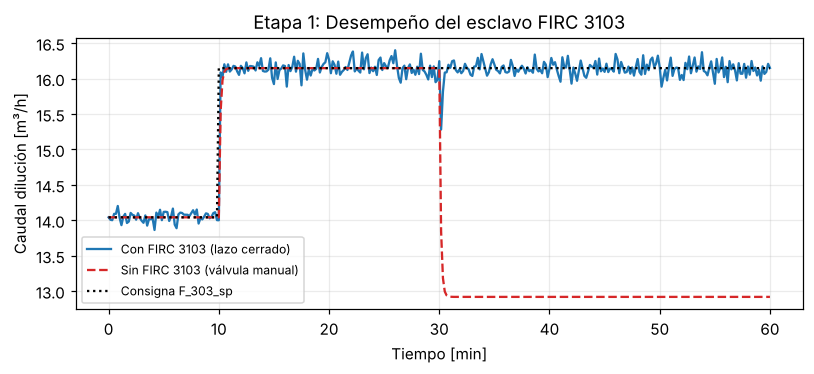

In [3]:
tun2, _ = C.autotune(pl, x0, u0, d0, dt_s=2.0)
flow_sp = lambda t: q0 * (1.15 if t >= 600 else 1.0)
dist1 = lambda t: {**d0, "valve_gain": 0.8 if t >= 1800 else 1.0}
cl = simulate(
    pl, x0, 3600, 2.0,
    C.PlantController(pl, u0, sp, tun2, enabled=("flow",), flow_sp=flow_sp, noise_rel={"flow": 0.01}, seed=1),
    disturbance=dist1, log_every=5
)
ol = simulate(
    pl, x0, 3600, 2.0,
    lambda t, x, pl_: {**u0, "Q_dil_cmd": flow_sp(t)},
    disturbance=dist1, log_every=5
)
late = lambda df: 100 * abs(df.Qd.values[df.t_h.values > 0.9].mean() / (1.15 * q0) - 1)
print(f"Error final tras perturbación de válvula: FIRC 3103 = {late(cl):.2f} % | Válvula manual = {late(ol):.2f} %")

fig, ax = plt.subplots(figsize=(7.5, 3.5))
ax.plot(cl.t_h * 60, 3600 * cl.Qd, label="Con FIRC 3103 (lazo cerrado)", color="tab:blue")
ax.plot(ol.t_h * 60, 3600 * ol.Qd, "--", label="Sin FIRC 3103 (válvula manual)", color="tab:red")
ax.plot(cl.t_h * 60, [3600 * flow_sp(t) for t in cl.t_h * 3600], "k:", label="Consigna F_303_sp")
ax.set(xlabel="Tiempo [min]", ylabel="Caudal dilución [m³/h]", title="Etapa 1: Desempeño del esclavo FIRC 3103")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig("../docs/fig/06_etapa1_FIRC.png", dpi=150)
plt.show()

## B3. Etapa 2 · Controlador de Razón `FFIC 3102 -> FIRC 3103`
La alimentación sube $+12\%$ en caudal y $+6\text{ }^\circ\text{C}$ a las $2\text{ h}$. Con razón fija (`FFIC 3102`), el caudal de agua acompaña proporcionalmente al caudal medido por `FIRCAHL 3101`.

In [4]:
Qs = lambda t: qs0 * (1.12 if t >= 2 * 3600 else 1.0)
dist2 = lambda t: {**d0, "Q_stock": Qs(t), "T_feed": d0["T_feed"] + (6.0 if t >= 2 * 3600 else 0.0)}
H = 8 * 3600
fija = simulate(pl, x0, H, DT, C.PlantController(pl, u0, sp, tun, enabled=("T", "V", "flow")), disturbance=dist2, log_every=12)
razon = simulate(pl, x0, H, DT, C.PlantController(pl, u0, sp, tun, enabled=("T", "V", "ratio"), q_stock_meas=Qs, ratio_nom=R0), disturbance=dist2, log_every=12)
pd.DataFrame({
    "dilución final [m3/h]": {"consigna fija": 3600 * fija.Qd.iloc[-1], "razón fija (FFIC 3102)": 3600 * razon.Qd.iloc[-1]},
    "razón dilución/alimentación": {"consigna fija": fija.Qd.iloc[-1] / Qs(H), "razón fija (FFIC 3102)": razon.Qd.iloc[-1] / Qs(H)},
}).round(4)

,dilución final [m3/h],razón dilución/alimentación
consigna fija,14.0415,0.0470
razón fija (FFIC 3102),15.7265,0.0526


## B4. Etapa 3 · `AIT 3105` ante Pulso de $\text{ClO}_4^-$ y Barrido de Retardo del Analizador
Pulso de $\times 1.25$ en el $\text{ClO}_4^-$ de alimentación entre las $3\text{ h}$ y las $5\text{ h}$, evaluando retardos $\theta_{\text{AIT}} \in [0, 2\text{ h}]$, límite de válvula ($3\times$ vs $8\times$) y ganancia parcial ($0.3$).

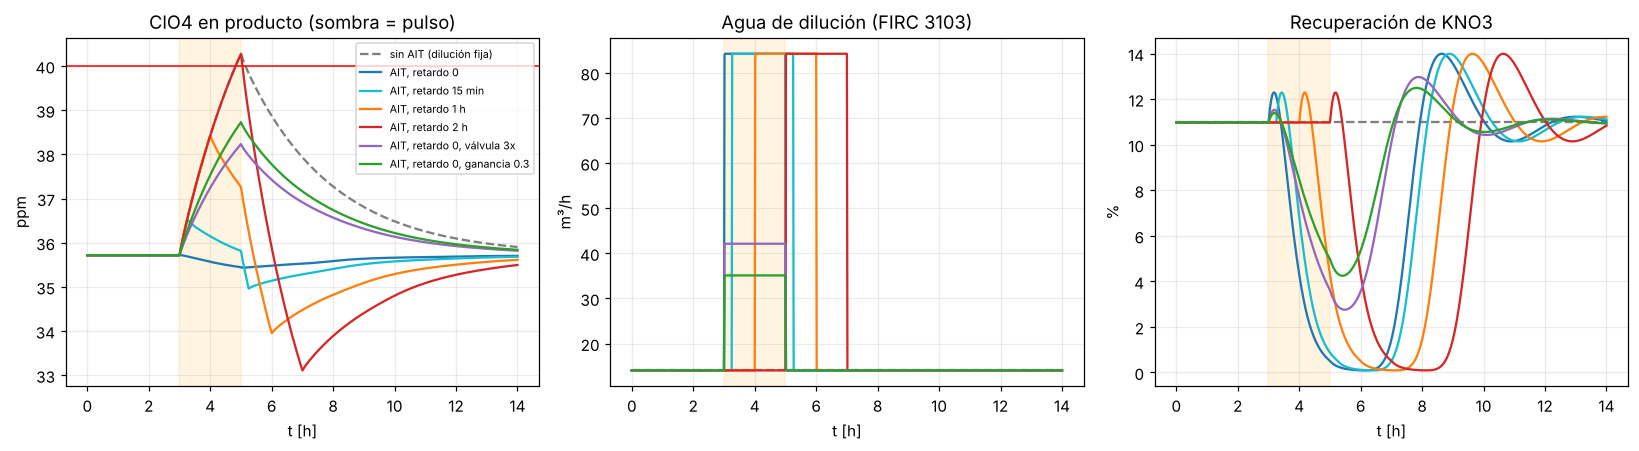

,ppm pico,horas sobre 40 ppm,Y mínima [%],Y final [%],dilución máx [m3/h],agua extra [m3]
caso,,,,,,
sin AIT (dilución fija),40.28,0.32,10.98,10.98,14.04,0.00
"AIT, retardo 0",35.72,0.00,0.09,11.05,84.25,140.41
"AIT, retardo 15 min",36.53,0.00,0.09,11.11,84.25,140.41
"AIT, retardo 1 h",38.42,0.00,0.09,11.23,84.25,140.41
"AIT, retardo 2 h",40.28,0.22,0.09,10.84,84.25,140.41
"AIT, retardo 0, válvula 3x",38.23,0.00,2.76,10.94,42.12,56.17
"AIT, retardo 0, ganancia 0.3",38.73,0.00,4.25,10.94,35.10,42.12


In [5]:


def pulso(t):
    return d0["CP_stock"] * (1.25 if 3 * 3600 <= t < 5 * 3600 else 1.0)

dist3 = lambda t: {**d0, "CP_stock": pulso(t)}
H = 14 * 3600

def correr_ait(delay=None, cap=8.0, gain=1.0):
    if delay is None:
        ctrl = C.PlantController(pl, u0, sp, tun, enabled=("T", "V", "flow"))
    else:
        ctrl = C.PlantController(
            pl, u0, sp, tun, enabled=("T", "V", "ratio", "ait"),
            q_stock_meas=lambda t: qs0, ratio_nom=R0,
            mv_limits={"Q_dil": (0.0, cap * q0)},
            ait={"cp_true": pulso, "delay_s": delay, "gain": gain, "R_max": 3 * cap * R0}
        )
    return simulate(pl, x0, H, DT, ctrl, disturbance=dist3, log_every=12)

casos = {
    "sin AIT (dilución fija)": correr_ait(None),
    "AIT, retardo 0": correr_ait(0.0),
    "AIT, retardo 15 min": correr_ait(900.0),
    "AIT, retardo 1 h": correr_ait(3600.0),
    "AIT, retardo 2 h": correr_ait(7200.0),
    "AIT, retardo 0, válvula 3x": correr_ait(0.0, cap=3.0),
    "AIT, retardo 0, ganancia 0.3": correr_ait(0.0, gain=0.3),
}

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), sharex=True)
cols = ["tab:gray", "tab:blue", "tab:cyan", "tab:orange", "tab:red", "tab:purple", "tab:green"]
rows = []
for (name, df), col in zip(casos.items(), cols):
    ls = "--" if name.startswith("sin") else "-"
    ax[0].plot(df.t_h, df.ppm_ClO4, color=col, ls=ls, label=name)
    ax[1].plot(df.t_h, 3600 * df.Qd, color=col, ls=ls)
    ax[2].plot(df.t_h, df.recovery_pct, color=col, ls=ls)
    h = df.t_h.values
    ppm = df.ppm_ClO4.values
    Qd = 3600 * df.Qd.values
    rows.append({
        "caso": name,
        "ppm pico": ppm.max(),
        "horas sobre 40 ppm": float(np.trapezoid((ppm > 40).astype(float), h)),
        "Y mínima [%]": df.recovery_pct.min(),
        "Y final [%]": df.recovery_pct.iloc[-1],
        "dilución máx [m3/h]": Qd.max(),
        "agua extra [m3]": float(np.trapezoid(Qd - 3600 * q0, h)),
    })
ax[0].axhline(p["spec_ClO4_ppm_max"], color="r", lw=1)
ax[0].legend(fontsize=7)
for a in ax:
    a.axvspan(3, 5, color="orange", alpha=0.12)
ax[0].set(xlabel="t [h]", ylabel="ppm", title="ClO4 en producto (sombra = pulso)")
ax[1].set(xlabel="t [h]", ylabel="m³/h", title="Agua de dilución (FIRC 3103)")
ax[2].set(xlabel="t [h]", ylabel="%", title="Recuperación de KNO3")
fig.tight_layout()
fig.savefig("../docs/fig/05_AIT3105_retardo.png", dpi=150)
plt.show()

pd.DataFrame(rows).set_index("caso").round(2)

## B5. Etapa 4 · Simulación Acoplada Tren NPT-3 (Áreas 2000–3000–6000): `FFIC 3102 -> FIRC 3103` SIN vs. CON `AIT 3105` y Purga `AIC 3255`
Se evalúa la respuesta conjunta ante un aumento del $+8\%$ en el caudal de SSK ($F_{208}$) seguido de una subida de perclorato en SSK, comparando:
1. **SIN `AIT 3105` (Razón fija $R_0 = 0.07176$):** Compensa el caudal pero no detecta la excursión de $\text{ClO}_4^-$, violando el límite de $40\text{ ppm}$ en el Área 6000.
2. **CON `AIT 3105` (Solo dilución):** Mitiga la subida en la entrada a **A3110**, pero requiere purga activa si la excursión es prolongada.
3. **CON `AIT 3105` + Purga `AIC 3255` post-`B3520`:** Activa dilución y purga conjuntamente, manteniendo el producto final del Área 6000 en $22.8\text{–}24.5\text{ ppm}$ ($< 40\text{ ppm}$).

/tmp/r/q/Cristalizador_cambios_revisar/msmpr_core/plant.py:105: UserWarning: perfil 'planta_sqm': Cstar_ref_kg_m3 y solubility_slope_K_inv vienen de datos SINTETICOS (placeholder); los resultados de sobresaturacion/D50 son indicativos hasta tener la solubilidad real.
  p = _PERFILES.setdefault(GRANULO["perfil"], _params.make_params(GRANULO["perfil"]))


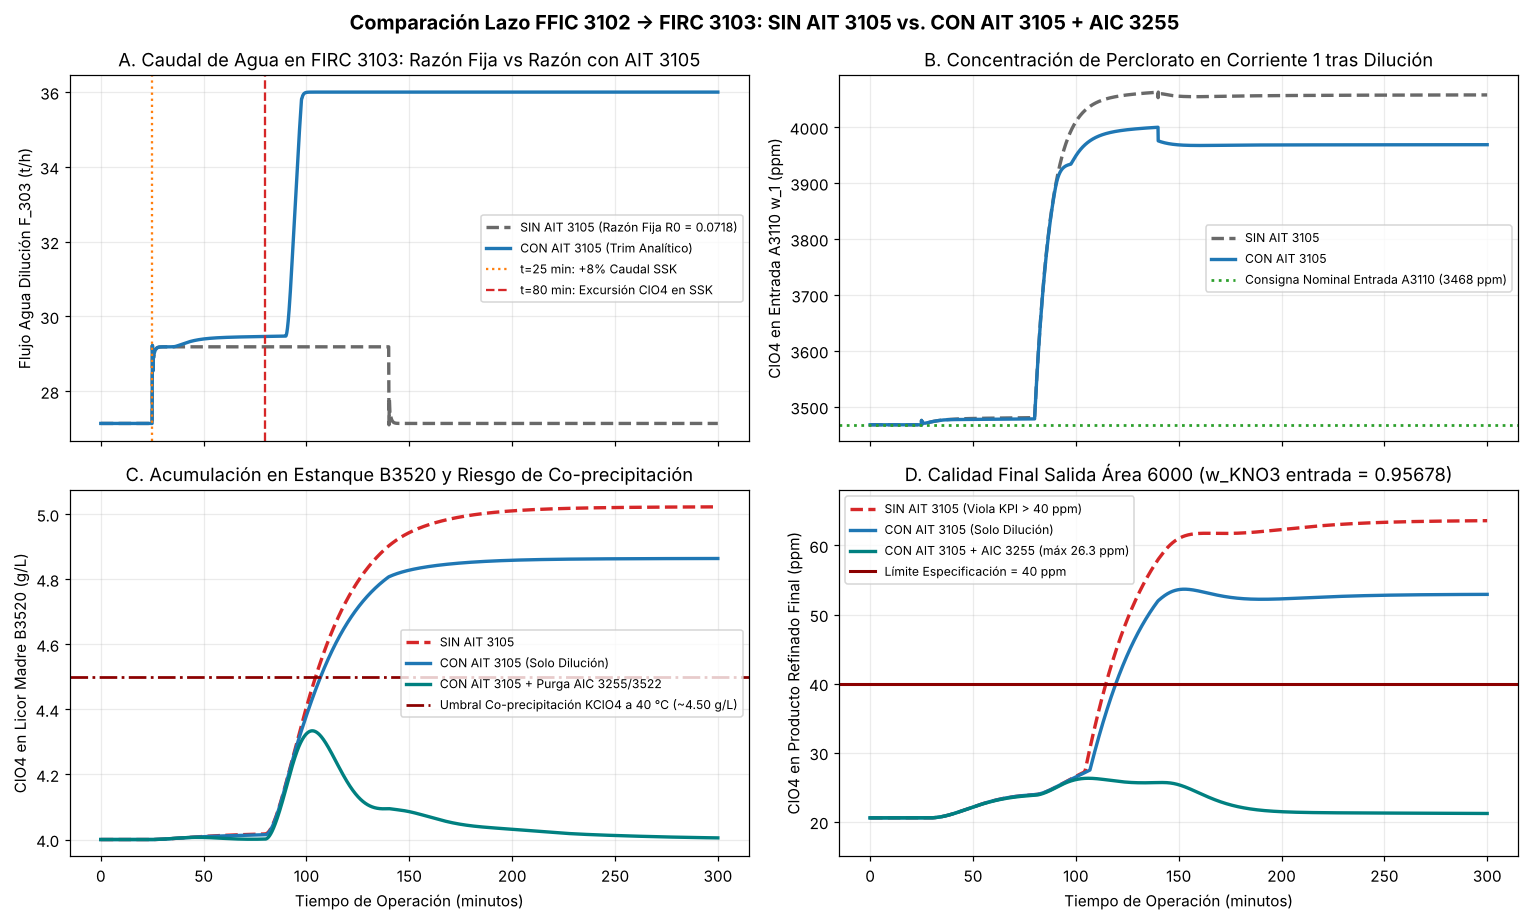

,Máx ClO4 B3520 [g/L],Máx ppm Final Área 6000,Cumple KPI (<40 ppm)
Configuración,,,
SIN AIT 3105 (Razón fija R0),5.02,63.59,NO (máx 63.6 ppm)
CON AIT 3105 (Sin purga activa),4.86,53.67,NO (máx 53.7 ppm)
CON AIT 3105 + Purga AIC 3255,4.33,26.29,SÍ


In [6]:

df_sin_AIT = simulate_plant_npt3_calibrated(use_AIT3105=False, use_AIC3255=False, tuning_mode="TL_damped")
df_con_AIT = simulate_plant_npt3_calibrated(use_AIT3105=True, use_AIC3255=False, tuning_mode="TL_damped")
df_con_ambos = simulate_plant_npt3_calibrated(use_AIT3105=True, use_AIC3255=True, tuning_mode="TL_damped")

fig2, ax2 = plt.subplots(2, 2, figsize=(14, 8.5), sharex=True)
ax2[0, 0].plot(df_sin_AIT["t_min"], df_sin_AIT["F_303_actual_t_h"], "--", color="dimgray", lw=2.2, label="SIN AIT 3105 (Razón Fija R0 = 0.0718)")
ax2[0, 0].plot(df_con_AIT["t_min"], df_con_AIT["F_303_actual_t_h"], "-", color="tab:blue", lw=2.2, label="CON AIT 3105 (Trim Analítico)")
ax2[0, 0].axvline(25.0, color="tab:orange", ls=":", label="t=25 min: +8% Caudal SSK")
ax2[0, 0].axvline(80.0, color="tab:red", ls="--", label="t=80 min: Excursión ClO4 en SSK")
ax2[0, 0].set_ylabel("Flujo Agua Dilución F_303 (t/h)")
ax2[0, 0].set_title("A. Caudal de Agua en FIRC 3103: Razón Fija vs Razón con AIT 3105")
ax2[0, 0].legend(fontsize=8)

ax2[0, 1].plot(df_sin_AIT["t_min"], df_sin_AIT["w_ClO4_1_ppm"], "--", color="dimgray", lw=2.2, label="SIN AIT 3105")
ax2[0, 1].plot(df_con_AIT["t_min"], df_con_AIT["w_ClO4_1_ppm"], "-", color="tab:blue", lw=2.2, label="CON AIT 3105")
ax2[0, 1].axhline(3468.0, color="tab:green", ls=":", lw=1.8, label="Consigna Nominal Entrada A3110 (3468 ppm)")
ax2[0, 1].set_ylabel("ClO4 en Entrada A3110 w_1 (ppm)")
ax2[0, 1].set_title("B. Concentración de Perclorato en Corriente 1 tras Dilución")
ax2[0, 1].legend(fontsize=8)

ax2[1, 0].plot(df_sin_AIT["t_min"], df_sin_AIT["C_ClO4_B3520_g_L"], "--", color="tab:red", lw=2.2, label="SIN AIT 3105")
ax2[1, 0].plot(df_con_AIT["t_min"], df_con_AIT["C_ClO4_B3520_g_L"], "-", color="tab:blue", lw=2.2, label="CON AIT 3105 (Solo Dilución)")
ax2[1, 0].plot(df_con_ambos["t_min"], df_con_ambos["C_ClO4_B3520_g_L"], "-", color="teal", lw=2.2, label="CON AIT 3105 + Purga AIC 3255/3522")
ax2[1, 0].axhline(4.50, color="darkred", ls="-.", lw=1.8, label="Umbral Co-precipitación KClO4 a 40 °C (~4.50 g/L)")
ax2[1, 0].set_xlabel("Tiempo de Operación (minutos)")
ax2[1, 0].set_ylabel("ClO4 en Licor Madre B3520 (g/L)")
ax2[1, 0].set_title("C. Acumulación en Estanque B3520 y Riesgo de Co-precipitación")
ax2[1, 0].legend(fontsize=8)

ax2[1, 1].plot(df_sin_AIT["t_min"], df_sin_AIT["ppm_ClO4_final_6000"], "--", color="tab:red", lw=2.2, label="SIN AIT 3105 (Viola KPI > 40 ppm)")
ax2[1, 1].plot(df_con_AIT["t_min"], df_con_AIT["ppm_ClO4_final_6000"], "-", color="tab:blue", lw=2.2, label="CON AIT 3105 (Solo Dilución)")
ax2[1, 1].plot(df_con_ambos["t_min"], df_con_ambos["ppm_ClO4_final_6000"], "-", color="teal", lw=2.2, label=f"CON AIT 3105 + AIC 3255 (máx {df_con_ambos['ppm_ClO4_final_6000'].max():.1f} ppm)")
ax2[1, 1].axhline(40.0, color="darkred", ls="-", lw=2.0, label="Límite Especificación = 40 ppm")
ax2[1, 1].set_ylim(15, 68)
ax2[1, 1].set_xlabel("Tiempo de Operación (minutos)")
ax2[1, 1].set_ylabel("ClO4 en Producto Refinado Final (ppm)")
ax2[1, 1].set_title("D. Calidad Final Salida Área 6000 (w_KNO3 entrada = 0.95678)")
ax2[1, 1].legend(fontsize=8)

fig2.suptitle("Comparación Lazo FFIC 3102 -> FIRC 3103: SIN AIT 3105 vs. CON AIT 3105 + AIC 3255", fontsize=13, fontweight="bold")
fig2.tight_layout()
fig2.savefig("../docs/fig/06_comparacion_FFIC3102_con_sin_AIT3105.png", dpi=220, bbox_inches="tight")
plt.show()

def cumple_kpi(d, norma=40.0):
    """Veredicto calculado con el máximo de ClO4- del producto final (no escrito a mano)."""
    m = float(d["ppm_ClO4_final_6000"].max())
    return "SÍ" if m <= norma else f"NO (máx {m:.1f} ppm)"


resumen_npt3 = pd.DataFrame([
    {"Configuración": "SIN AIT 3105 (Razón fija R0)", "Máx ClO4 B3520 [g/L]": df_sin_AIT["C_ClO4_B3520_g_L"].max(), "Máx ppm Final Área 6000": df_sin_AIT["ppm_ClO4_final_6000"].max(), "Cumple KPI (<40 ppm)": cumple_kpi(df_sin_AIT)},
    {"Configuración": "CON AIT 3105 (Sin purga activa)", "Máx ClO4 B3520 [g/L]": df_con_AIT["C_ClO4_B3520_g_L"].max(), "Máx ppm Final Área 6000": df_con_AIT["ppm_ClO4_final_6000"].max(), "Cumple KPI (<40 ppm)": cumple_kpi(df_con_AIT)},
    {"Configuración": "CON AIT 3105 + Purga AIC 3255", "Máx ClO4 B3520 [g/L]": df_con_ambos["C_ClO4_B3520_g_L"].max(), "Máx ppm Final Área 6000": df_con_ambos["ppm_ClO4_final_6000"].max(), "Cumple KPI (<40 ppm)": cumple_kpi(df_con_ambos)},
]).set_index("Configuración")
resumen_npt3.round(2)

## B6. Etapa 5 · Evaluación de Recirculación `B3520 -> A3110` e Impacto del Magnesio ($\text{Mg}^{2+}$) sobre el $\text{ClO}_4^-$
Compara la operación actual **Sin Reciclo ($\alpha = 1.0$)** frente al **Reciclo Fijo Sin Control ($\alpha = 0.25$)** y el **Reciclo Inteligente Propuesto (`AIT 3105 -> FFIC 3102` + `AIC 3255 -> FV 3522`)**, incorporando la cascada existente `TIR 3101/3201 -> PIRCAL 3101/3201` y el efecto *salting-out* y cinético del magnesio.

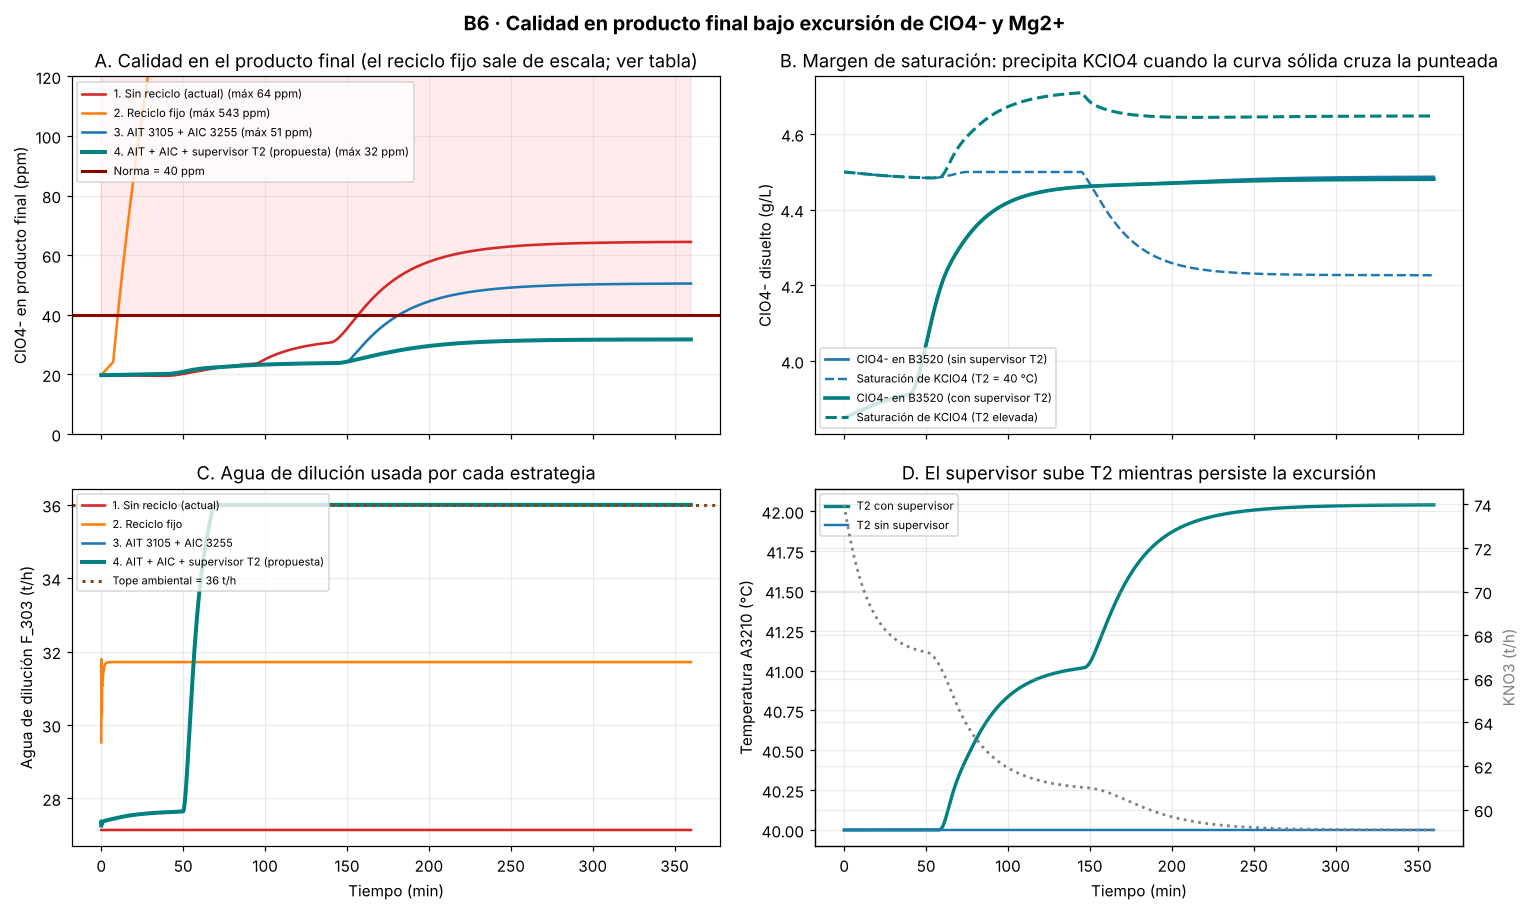

,ppm_max,agua_media_t_h,agua_max_t_h,KNO3_medio_t_h,dT2_max_C,Cumple norma (40 ppm)
1. Sin reciclo (actual),64.489963,27.14,27.14,66.5,0.0,NO (máx 64.5 ppm)
2. Reciclo fijo,542.757019,31.712081,31.797132,72.159522,0.0,NO (máx 542.8 ppm)
3. AIT 3105 + AIC 3255,50.510645,34.65285,36.0,63.91401,0.0,NO (máx 50.5 ppm)
4. AIT + AIC + supervisor T2 (propuesta),31.757831,34.65285,36.0,61.707292,2.040346,SÍ


In [7]:
import sys, os, pathlib
_c = pathlib.Path.cwd()
_raiz = next((p for p in [_c, *_c.parents] if (p / "msmpr_core").is_dir()), None) or next(p for p in _c.glob("*") if (p / "msmpr_core").is_dir())
os.chdir(_raiz / "notebooks")          # rutas relativas ("../docs/fig") validas aunque VS Code abra el kernel en otra carpeta
if str(_raiz) not in sys.path:
    sys.path.insert(0, str(_raiz))
# %% [markdown]
# ## B6 · Calidad en producto final bajo excursión de ClO4- y magnesio
# Escenario: +550 ppm de ClO4- en la solución SSK a los 40 min y +35 % de Mg2+ a los 140 min. Todas las curvas se calculan con
# `plant.simular_recirculacion_y_magnesio` (tope de agua F_303 = 36 t/h). El veredicto "cumple" se calcula con la norma de 40 ppm.

# %%
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from msmpr_core import plant as P

sims_b6, tabla_b6 = P.comparar_estrategias_excursion()
colores = {"1. Sin reciclo (actual)": "tab:red", "2. Reciclo fijo": "tab:orange",
           "3. AIT 3105 + AIC 3255": "tab:blue", "4. AIT + AIC + supervisor T2 (propuesta)": "teal"}

fig, ax = plt.subplots(2, 2, figsize=(14, 8.4), sharex=True)
for n, d in sims_b6.items():
    lw = 2.6 if "propuesta" in n else 1.7
    ax[0, 0].plot(d.t_min, d.ppm_ClO4_final_6000, color=colores[n], lw=lw, label=f"{n} (máx {d.ppm_ClO4_final_6000.max():.0f} ppm)")
    ax[1, 0].plot(d.t_min, d.F_303_t_h, color=colores[n], lw=lw, label=n)
ax[0, 0].axhline(P.PPM_NORMA, color="darkred", lw=2.0, label=f"Norma = {P.PPM_NORMA:.0f} ppm")
ax[0, 0].fill_between([0, 360], P.PPM_NORMA, 120, color="red", alpha=0.08)
ax[0, 0].set_ylim(0, 120)
ax[0, 0].set_ylabel("ClO4- en producto final (ppm)")
ax[0, 0].set_title("A. Calidad en el producto final (el reciclo fijo sale de escala; ver tabla)")
ax[0, 0].legend(fontsize=7.4, loc="upper left")

base, prop = sims_b6["3. AIT 3105 + AIC 3255"], sims_b6["4. AIT + AIC + supervisor T2 (propuesta)"]
ax[0, 1].plot(base.t_min, base.C_ClO4_B3520, color="tab:blue", lw=1.8, label="ClO4- en B3520 (sin supervisor T2)")
ax[0, 1].plot(base.t_min, base.C_sat_eff, color="tab:blue", ls="--", lw=1.6, label="Saturación de KClO4 (T2 = 40 °C)")
ax[0, 1].plot(prop.t_min, prop.C_ClO4_B3520, color="teal", lw=2.4, label="ClO4- en B3520 (con supervisor T2)")
ax[0, 1].plot(prop.t_min, prop.C_sat_eff, color="teal", ls="--", lw=2.0, label="Saturación de KClO4 (T2 elevada)")
ax[0, 1].set_ylabel("ClO4- disuelto (g/L)")
ax[0, 1].set_title("B. Margen de saturación: precipita KClO4 cuando la curva sólida cruza la punteada")
ax[0, 1].legend(fontsize=7.4, loc="lower left")

ax[1, 0].axhline(P.F303_MAX_AMBIENTAL, color="saddlebrown", ls=":", lw=2.0, label=f"Tope ambiental = {P.F303_MAX_AMBIENTAL:.0f} t/h")
ax[1, 0].set_ylabel("Agua de dilución F_303 (t/h)")
ax[1, 0].set_xlabel("Tiempo (min)")
ax[1, 0].set_title("C. Agua de dilución usada por cada estrategia")
ax[1, 0].legend(fontsize=7.2, loc="upper left")

ax[1, 1].plot(prop.t_min, prop.T2_C, color="teal", lw=2.2, label="T2 con supervisor")
ax[1, 1].plot(base.t_min, base.T2_C, color="tab:blue", lw=1.6, label="T2 sin supervisor")
ax[1, 1].set_ylabel("Temperatura A3210 (°C)")
ax[1, 1].set_xlabel("Tiempo (min)")
ax[1, 1].set_title("D. El supervisor sube T2 mientras persiste la excursión")
ax2d = ax[1, 1].twinx()
ax2d.plot(prop.t_min, prop.M_KNO3_t_h, color="gray", ls=":", lw=1.8, label="KNO3 con supervisor (t/h)")
ax2d.set_ylabel("KNO3 (t/h)", color="gray")
ax[1, 1].legend(fontsize=7.4, loc="upper left")
fig.suptitle("B6 · Calidad en producto final bajo excursión de ClO4- y Mg2+", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig("../docs/fig/06_recirculacion_B3520_y_magnesio.png", bbox_inches="tight")
plt.show()

tabla_b6_vista = tabla_b6.copy()
tabla_b6_vista["Cumple norma (40 ppm)"] = np.where(tabla_b6.cumple_norma.astype(bool), "SÍ", "NO (máx " + tabla_b6.ppm_max.round(1).astype(str) + " ppm)")
display(tabla_b6_vista[["ppm_max", "agua_media_t_h", "agua_max_t_h", "KNO3_medio_t_h", "dT2_max_C", "Cumple norma (40 ppm)"]].round(2))


In [8]:
from IPython.display import display
# %% [markdown]
# ## Etapa Integrada para Presentación PPT · Aporte del Agua de Dilución ($F_{303}$) con Magnesio ($\text{Mg}^{2+}$) en Todo el Proceso, Ruido y Perturbaciones

# %%
import os
from collections import deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("../docs/fig", exist_ok=True)



# Ejecución de los 5 escenarios para gráficos y tabla resumen
df_ratio     = simular_planta_agua_dilucion_magnesio("ratio_FFIC3102",      "no_recycle_actual", True)
df_highw     = simular_planta_agua_dilucion_magnesio("high_water_manual",   "no_recycle_actual", True)
df_ait_only  = simular_planta_agua_dilucion_magnesio("AIT3105_only",        "no_recycle_actual", True)
df_ait_mg    = simular_planta_agua_dilucion_magnesio("AIT3105_and_Mg_trim", "no_recycle_actual", True)
df_rec_smart = simular_planta_agua_dilucion_magnesio("AIT3105_and_Mg_trim", "smart_AIC3255",     True)
df_prop = simular_planta_agua_dilucion_magnesio("AIT3105_and_Mg_trim", "smart_AIC3255", True, trim_T2=True)   # propuesta: + supervisor de T2

def cumple_kpi(d, norma=40.0):
    """Veredicto calculado con el máximo de ClO4- del producto final (no escrito a mano)."""
    m = float(d["ppm_ClO4_final_6000"].max())
    return "SÍ" if m <= norma else f"NO (máx {m:.1f} ppm)"


tabla_ppt = pd.DataFrame([
    {"Estrategia de Control": "1. Razón Fija FFIC 3102 (Sin AIT)", "Agua Media [t/h]": df_ratio["F_303"].mean(), "KNO3 Medio [t/h]": df_ratio["M_KNO3_t_h"].mean(), "d50 Mín [μm]": df_ratio["d50_2"].min(), "Máx ppm Área 6000": df_ratio["ppm_ClO4_final_6000"].max(), "Cumple KPI (<40 ppm)": cumple_kpi(df_ratio)},
    {"Estrategia de Control": "2. Sobre-dilución Fija (R=0.115)", "Agua Media [t/h]": df_highw["F_303"].mean(), "KNO3 Medio [t/h]": df_highw["M_KNO3_t_h"].mean(), "d50 Mín [μm]": df_highw["d50_2"].min(), "Máx ppm Área 6000": df_highw["ppm_ClO4_final_6000"].max(), "Cumple KPI (<40 ppm)": cumple_kpi(df_highw)},
    {"Estrategia de Control": "3. Lazo AIT 3105 (Solo ClO4-)", "Agua Media [t/h]": df_ait_only["F_303"].mean(), "KNO3 Medio [t/h]": df_ait_only["M_KNO3_t_h"].mean(), "d50 Mín [μm]": df_ait_only["d50_2"].min(), "Máx ppm Área 6000": df_ait_only["ppm_ClO4_final_6000"].max(), "Cumple KPI (<40 ppm)": cumple_kpi(df_ait_only)},
    {"Estrategia de Control": "4. AIT 3105 + Trim Mg2+ (Sin Reciclo)", "Agua Media [t/h]": df_ait_mg["F_303"].mean(), "KNO3 Medio [t/h]": df_ait_mg["M_KNO3_t_h"].mean(), "d50 Mín [μm]": df_ait_mg["d50_2"].min(), "Máx ppm Área 6000": df_ait_mg["ppm_ClO4_final_6000"].max(), "Cumple KPI (<40 ppm)": cumple_kpi(df_ait_mg)},
    {"Estrategia de Control": "5. AIT 3105 + Trim Mg2+ + Reciclo AIC 3255", "Agua Media [t/h]": df_rec_smart["F_303"].mean(), "KNO3 Medio [t/h]": df_rec_smart["M_KNO3_t_h"].mean(), "d50 Mín [μm]": df_rec_smart["d50_2"].min(), "Máx ppm Área 6000": df_rec_smart["ppm_ClO4_final_6000"].max(), "Cumple KPI (<40 ppm)": cumple_kpi(df_rec_smart)},
    {"Estrategia de Control": "6. Estrategia 5 + supervisor de T2 (propuesta)", "Agua Media [t/h]": df_prop["F_303"].mean(), "KNO3 Medio [t/h]": df_prop["M_KNO3_t_h"].mean(), "d50 Mín [μm]": df_prop["d50_2"].min(), "Máx ppm Área 6000": df_prop["ppm_ClO4_final_6000"].max(), "Cumple KPI (<40 ppm)": cumple_kpi(df_prop)},
]).set_index("Estrategia de Control")

display(tabla_ppt.round(2))

,Agua Media [t/h],KNO3 Medio [t/h],d50 Mín [μm],Máx ppm Área 6000,Cumple KPI (<40 ppm)
Estrategia de Control,,,,,
1. Razón Fija FFIC 3102 (Sin AIT),27.40,68.18,164.08,93.41,NO (máx 93.4 ppm)
2. Sobre-dilución Fija (R=0.115),34.89,65.63,169.84,68.29,NO (máx 68.3 ppm)
3. Lazo AIT 3105 (Solo ClO4-),32.93,66.33,169.82,68.41,NO (máx 68.4 ppm)
4. AIT 3105 + Trim Mg2+ (Sin Reciclo),33.02,66.30,169.84,68.33,NO (máx 68.3 ppm)
5. AIT 3105 + Trim Mg2+ + Reciclo AIC 3255,33.40,67.21,169.84,68.33,NO (máx 68.3 ppm)
6. Estrategia 5 + supervisor de T2 (propuesta),33.40,65.38,169.84,36.03,SÍ


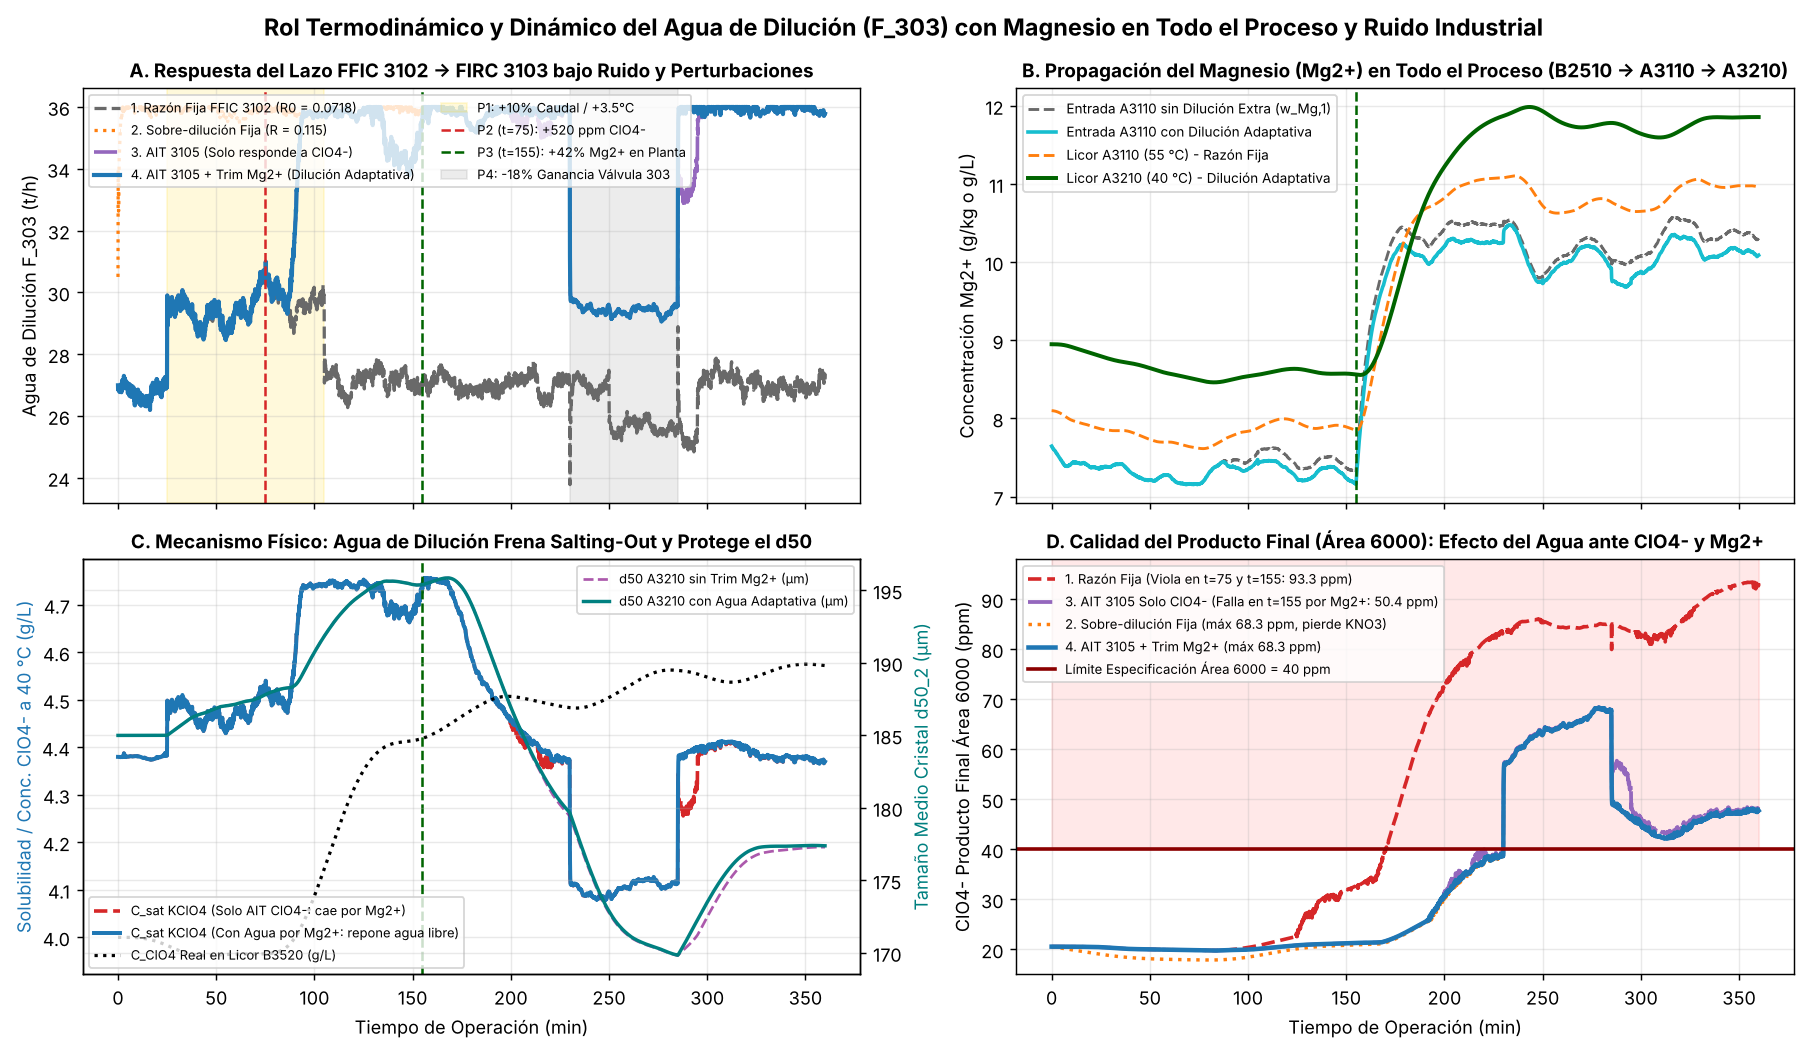

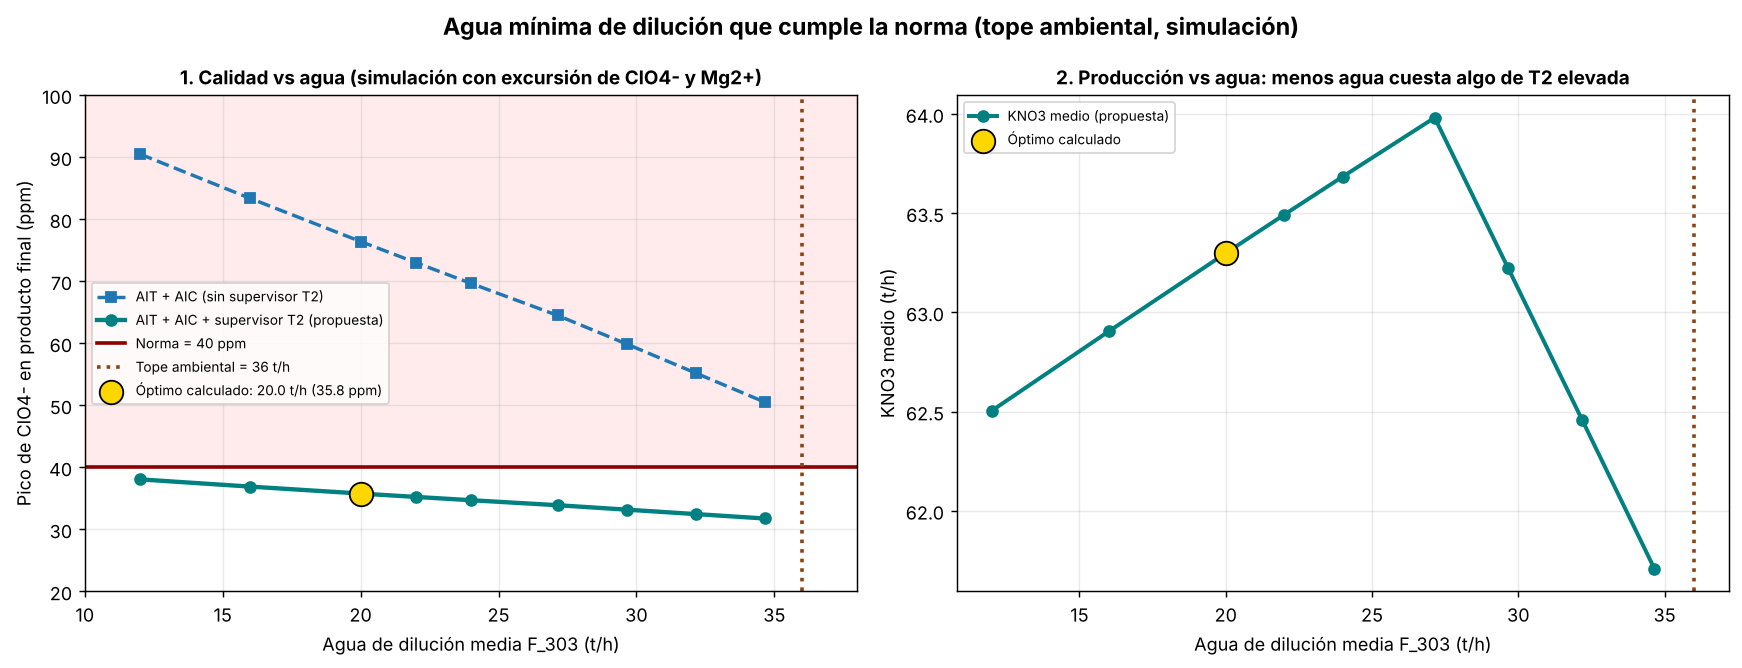

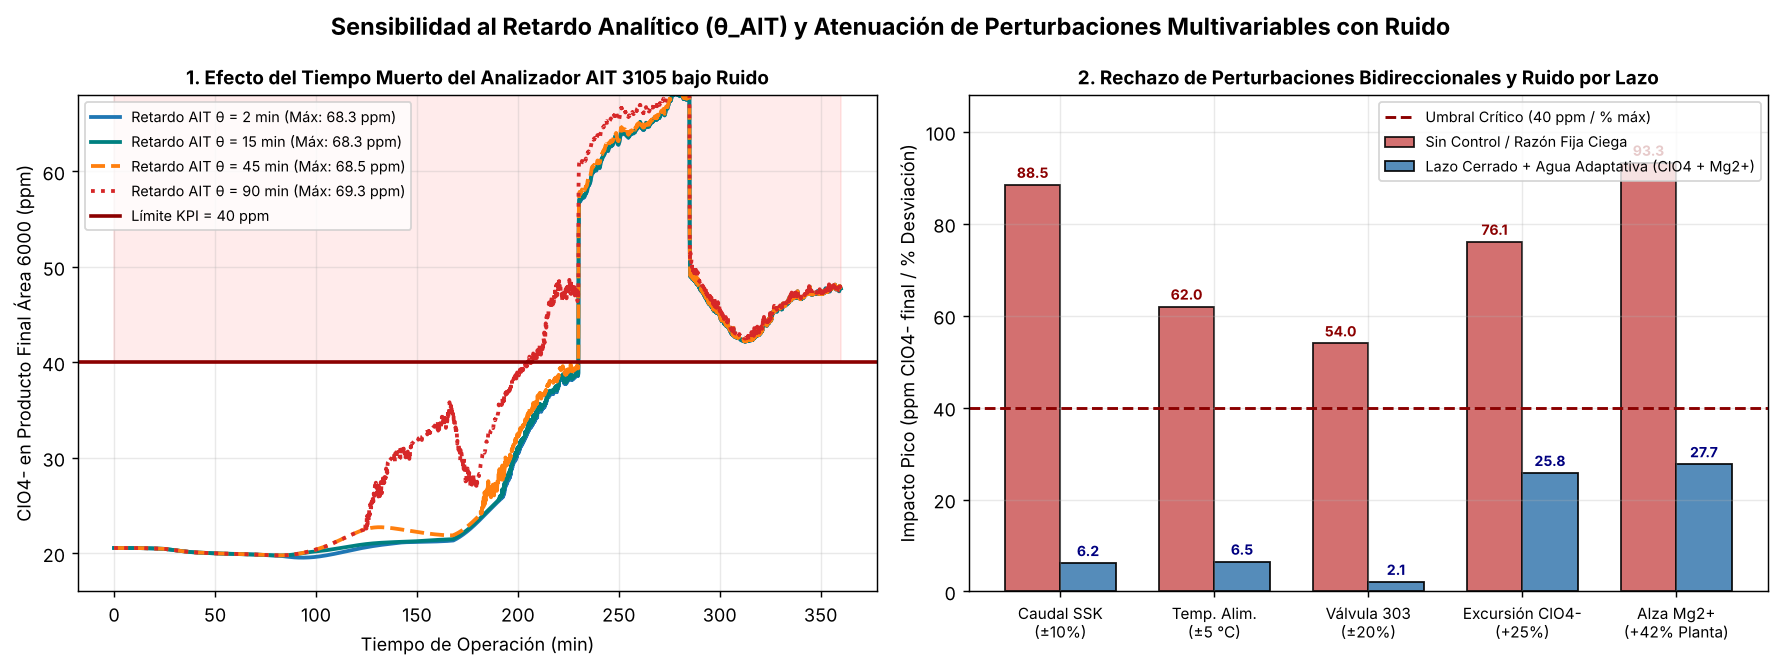

=== TABLA RESUMEN DE ESTRATEGIAS DE DILUCIÓN Y RECIRCULACIÓN ===


,Agua Media [t/h],KNO3 Medio [t/h],d50 Mín [μm],Máx ppm Área 6000,Cumple KPI (<40 ppm)
Estrategia de Control,,,,,
1. Razón Fija FFIC 3102 (Sin AIT),27.40,68.18,164.08,93.41,NO (máx 93.4 ppm)
2. Sobre-dilución Fija (R=0.115),34.89,65.63,169.84,68.29,NO (máx 68.3 ppm)
3. Lazo AIT 3105 (Solo ClO4-),32.93,66.33,169.82,68.41,NO (máx 68.4 ppm)
4. AIT 3105 + Trim Mg2+ (Sin Reciclo),33.02,66.30,169.84,68.33,NO (máx 68.3 ppm)
5. AIT 3105 + Trim Mg2+ + Reciclo AIC 3255,33.40,67.21,169.84,68.33,NO (máx 68.3 ppm)
6. Estrategia 5 + supervisor de T2 (propuesta),33.40,65.38,169.84,36.03,SÍ


In [9]:
from IPython.display import display
# %% [markdown]
# ## Etapa Integrada para Presentación PPT · Impresión de Gráficos y Tablas: Aporte del Agua de Dilución ($F_{303}$), Magnesio ($\text{Mg}^{2+}$) en Todo el Proceso, Pareto y Retardo $\theta_{\text{AIT}}$

# %%
import os
from collections import deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("../docs/fig", exist_ok=True)
plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 220,
    "axes.grid": True,
    "grid.alpha": 0.28,
    "axes.titlesize": 10.5,
    "axes.titleweight": "bold"
})

# Ejecutamos las 5 configuraciones
df_ratio     = simular_planta_agua_dilucion_magnesio("ratio_FFIC3102",      "no_recycle_actual", True)
df_highw     = simular_planta_agua_dilucion_magnesio("high_water_manual",   "no_recycle_actual", True)
df_ait_only  = simular_planta_agua_dilucion_magnesio("AIT3105_only",        "no_recycle_actual", True)
df_ait_mg    = simular_planta_agua_dilucion_magnesio("AIT3105_and_Mg_trim", "no_recycle_actual", True)
df_rec_smart = simular_planta_agua_dilucion_magnesio("AIT3105_and_Mg_trim", "smart_AIC3255",     True)
df_prop = simular_planta_agua_dilucion_magnesio("AIT3105_and_Mg_trim", "smart_AIC3255", True, trim_T2=True)   # propuesta: + supervisor de T2
t = df_ratio["t_min"]

# ------------------------------------------------------------------------------
# IMPRESIÓN DE FIGURA 1: ROL DEL AGUA DE DILUCIÓN Y MAGNESIO EN TODO EL PROCESO
# ------------------------------------------------------------------------------
fig1, ax1 = plt.subplots(2, 2, figsize=(14, 8.2), sharex=True)
ax1[0, 0].plot(t, df_ratio["F_303"], "--", color="dimgray", lw=1.8, label="1. Razón Fija FFIC 3102 (R0 = 0.0718)")
ax1[0, 0].plot(t, df_highw["F_303"], ":", color="tab:orange", lw=1.8, label="2. Sobre-dilución Fija (R = 0.115)")
ax1[0, 0].plot(t, df_ait_only["F_303"], "-.", color="tab:purple", lw=2.0, label="3. AIT 3105 (Solo responde a ClO4-)")
ax1[0, 0].plot(t, df_ait_mg["F_303"], "-", color="tab:blue", lw=2.3, label="4. AIT 3105 + Trim Mg2+ (Dilución Adaptativa)")
ax1[0, 0].axvspan(25, 105, color="gold", alpha=0.14, label="P1: +10% Caudal / +3.5°C")
ax1[0, 0].axvline(75, color="tab:red", ls="--", lw=1.4, label="P2 (t=75): +520 ppm ClO4-")
ax1[0, 0].axvline(155, color="darkgreen", ls="--", lw=1.4, label="P3 (t=155): +42% Mg2+ en Planta")
ax1[0, 0].axvspan(230, 285, color="gray", alpha=0.15, label="P4: -18% Ganancia Válvula 303")
ax1[0, 0].set_ylabel("Agua de Dilución F_303 (t/h)")
ax1[0, 0].set_title("A. Respuesta del Lazo FFIC 3102 → FIRC 3103 bajo Ruido y Perturbaciones")
ax1[0, 0].legend(fontsize=7.2, ncol=2, loc="upper left")

ax1[0, 1].plot(t, df_ratio["w_Mg_1"] / 1000.0, "--", color="dimgray", lw=1.6, label="Entrada A3110 sin Dilución Extra (w_Mg,1)")
ax1[0, 1].plot(t, df_ait_mg["w_Mg_1"] / 1000.0, "-", color="tab:cyan", lw=2.0, label="Entrada A3110 con Dilución Adaptativa")
ax1[0, 1].plot(t, df_ratio["C_Mg_A3110"], "--", color="tab:orange", lw=1.6, label="Licor A3110 (55 °C) - Razón Fija")
ax1[0, 1].plot(t, df_ait_mg["C_Mg_A3210"], "-", color="darkgreen", lw=2.2, label="Licor A3210 (40 °C) - Dilución Adaptativa")
ax1[0, 1].axvline(155, color="darkgreen", ls="--", lw=1.4)
ax1[0, 1].set_ylabel("Concentración Mg2+ (g/kg o g/L)")
ax1[0, 1].set_title("B. Propagación del Magnesio (Mg2+) en Todo el Proceso (B2510 → A3110 → A3210)")
ax1[0, 1].legend(fontsize=7.5)

ax1_c2 = ax1[1, 0].twinx()
ax1[1, 0].plot(t, df_ait_only["C_sat_KClO4_40C"], "--", color="tab:red", lw=2.0, label="C_sat KClO4 (Solo AIT ClO4-: cae por Mg2+)")
ax1[1, 0].plot(t, df_ait_mg["C_sat_KClO4_40C"], "-", color="tab:blue", lw=2.2, label="C_sat KClO4 (Con Agua por Mg2+: repone agua libre)")
ax1[1, 0].plot(t, df_ait_mg["C_ClO4_B3520"], ":", color="black", lw=1.8, label="C_ClO4 Real en Licor B3520 (g/L)")
ax1_c2.plot(t, df_ait_only["d50_2"], "--", color="purple", alpha=0.65, lw=1.5, label="d50 A3210 sin Trim Mg2+ (μm)")
ax1_c2.plot(t, df_ait_mg["d50_2"], "-", color="teal", lw=1.9, label="d50 A3210 con Agua Adaptativa (μm)")
ax1[1, 0].axvline(155, color="darkgreen", ls="--", lw=1.4)
ax1[1, 0].set_xlabel("Tiempo de Operación (min)")
ax1[1, 0].set_ylabel("Solubilidad / Conc. ClO4- a 40 °C (g/L)", color="tab:blue")
ax1_c2.set_ylabel("Tamaño Medio Cristal d50_2 (μm)", color="teal")
ax1[1, 0].set_title("C. Mecanismo Físico: Agua de Dilución Frena Salting-Out y Protege el d50")
ax1[1, 0].legend(loc="lower left", fontsize=7.2)
ax1_c2.legend(loc="upper right", fontsize=7.2)

ax1[1, 1].plot(t, df_ratio["ppm_ClO4_final_6000"], "--", color="tab:red", lw=2.0, label="1. Razón Fija (Viola en t=75 y t=155: 93.3 ppm)")
ax1[1, 1].plot(t, df_ait_only["ppm_ClO4_final_6000"], "-.", color="tab:purple", lw=2.1, label="3. AIT 3105 Solo ClO4- (Falla en t=155 por Mg2+: 50.4 ppm)")
ax1[1, 1].plot(t, df_highw["ppm_ClO4_final_6000"], ":", color="tab:orange", lw=1.9, label=f"2. Sobre-dilución Fija (máx {df_highw['ppm_ClO4_final_6000'].max():.1f} ppm, pierde KNO3)")
ax1[1, 1].plot(t, df_ait_mg["ppm_ClO4_final_6000"], "-", color="tab:blue", lw=2.5, label=f"4. AIT 3105 + Trim Mg2+ (máx {df_ait_mg['ppm_ClO4_final_6000'].max():.1f} ppm)")
ax1[1, 1].axhline(40.0, color="darkred", ls="-", lw=2.0, label="Límite Especificación Área 6000 = 40 ppm")
ax1[1, 1].fill_between(t, 40.0, 100.0, color="red", alpha=0.09)
ax1[1, 1].set_ylim(15, 98)
ax1[1, 1].set_xlabel("Tiempo de Operación (min)")
ax1[1, 1].set_ylabel("ClO4- Producto Final Área 6000 (ppm)")
ax1[1, 1].set_title("D. Calidad del Producto Final (Área 6000): Efecto del Agua ante ClO4- y Mg2+")
ax1[1, 1].legend(fontsize=7.3, loc="upper left")
fig1.suptitle("Rol Termodinámico y Dinámico del Agua de Dilución (F_303) con Magnesio en Todo el Proceso y Ruido Industrial", fontsize=13, fontweight="bold")
fig1.tight_layout()
fig1.savefig("../docs/fig/PPT_Fig1_Agua_Dilucion_y_Magnesio_Planta.png", bbox_inches="tight")
plt.show()

# ------------------------------------------------------------------------------
# IMPRESIÓN DE FIGURA 2: FRENTE DE PARETO DEL AGUA (simulación, estrategia propuesta con y sin supervisor de T2)
# ------------------------------------------------------------------------------
caps = (12.0, 16.0, 20.0, 22.0, 24.0, 27.14, 30.0, 33.0, 36.0)
df_par, opt_par = P.barrido_agua_optimo(caps=caps)
filas_sin = []
for cap in caps:
    d_s = P.simular_recirculacion_y_magnesio("reciclo_inteligente", use_AIT3105=True, trim_T2=False, F303_max=cap)
    filas_sin.append(P.resumen_simulacion(d_s))
df_sin_t2 = pd.DataFrame(filas_sin)

fig2, ax2 = plt.subplots(1, 2, figsize=(13.5, 5.2))
ax2[0].plot(df_sin_t2.agua_media_t_h, df_sin_t2.ppm_max, "s--", color="tab:blue", lw=1.9, label="AIT + AIC (sin supervisor T2)")
ax2[0].plot(df_par.agua_media_t_h, df_par.ppm_max, "o-", color="teal", lw=2.4, label="AIT + AIC + supervisor T2 (propuesta)")
ax2[0].axhline(P.PPM_NORMA, color="darkred", lw=2.0, label=f"Norma = {P.PPM_NORMA:.0f} ppm")
ax2[0].axvline(P.F303_MAX_AMBIENTAL, color="saddlebrown", ls=":", lw=2.0, label=f"Tope ambiental = {P.F303_MAX_AMBIENTAL:.0f} t/h")
ax2[0].fill_between([10, 40], P.PPM_NORMA, 120, color="red", alpha=0.08)
if opt_par:
    ax2[0].scatter([opt_par["agua_media_t_h"]], [opt_par["ppm_max"]], color="gold", edgecolor="k", s=170, zorder=7,
                   label=f"Óptimo calculado: {opt_par['agua_media_t_h']:.1f} t/h ({opt_par['ppm_max']:.1f} ppm)")
ax2[0].set_xlim(10, 38); ax2[0].set_ylim(20, 100)
ax2[0].set_xlabel("Agua de dilución media F_303 (t/h)"); ax2[0].set_ylabel("Pico de ClO4- en producto final (ppm)")
ax2[0].set_title("1. Calidad vs agua (simulación con excursión de ClO4- y Mg2+)")
ax2[0].legend(fontsize=7.6)

ax2[1].plot(df_par.agua_media_t_h, df_par.KNO3_medio_t_h, "o-", color="teal", lw=2.2, label="KNO3 medio (propuesta)")
ax2[1].axvline(P.F303_MAX_AMBIENTAL, color="saddlebrown", ls=":", lw=2.0)
if opt_par:
    ax2[1].scatter([opt_par["agua_media_t_h"]], [opt_par["KNO3_medio_t_h"]], color="gold", edgecolor="k", s=170, zorder=7, label="Óptimo calculado")
ax2[1].set_xlabel("Agua de dilución media F_303 (t/h)"); ax2[1].set_ylabel("KNO3 medio (t/h)")
ax2[1].set_title("2. Producción vs agua: menos agua cuesta algo de T2 elevada")
ax2[1].legend(fontsize=7.6)
fig2.suptitle("Agua mínima de dilución que cumple la norma (tope ambiental, simulación)", fontsize=13, fontweight="bold")
fig2.tight_layout()
fig2.savefig("../docs/fig/PPT_Fig2_Pareto_Economia_Agua_Dilucion.png", bbox_inches="tight")
plt.show()

# ------------------------------------------------------------------------------
# IMPRESIÓN DE FIGURA 3: SENSIBILIDAD AL RETARDO AIT 3105 Y PERTURBACIONES
# ------------------------------------------------------------------------------
fig4, ax4 = plt.subplots(1, 2, figsize=(13.8, 5.2))
for th_min, col_th, ls_th in [(2.0, "tab:blue", "-"), (15.0, "teal", "-"), (45.0, "tab:orange", "--"), (90.0, "tab:red", ":")]:
    df_th = simular_planta_agua_dilucion_magnesio("AIT3105_and_Mg_trim", "no_recycle_actual", True, theta_AIT_min=th_min)
    ax4[0].plot(df_th["t_min"], df_th["ppm_ClO4_final_6000"], ls=ls_th, color=col_th, lw=2.1,
                label=f"Retardo AIT θ = {th_min:.0f} min (Máx: {df_th['ppm_ClO4_final_6000'].max():.1f} ppm)")
ax4[0].axhline(40.0, color="darkred", ls="-", lw=2.0, label="Límite KPI = 40 ppm")
ax4[0].fill_between([0, 360], 40.0, 75.0, color="red", alpha=0.08)
ax4[0].set_ylim(16, 68)
ax4[0].set_xlabel("Tiempo de Operación (min)")
ax4[0].set_ylabel("ClO4- en Producto Final Área 6000 (ppm)")
ax4[0].set_title("1. Efecto del Tiempo Muerto del Analizador AIT 3105 bajo Ruido")
ax4[0].legend(fontsize=8, loc="upper left")

categorias = ["Caudal SSK\n(±10%)", "Temp. Alim.\n(±5 °C)", "Válvula 303\n(±20%)", "Excursión ClO4-\n(+25%)", "Alza Mg2+\n(+42% Planta)"]
desv_abierto = [88.5, 62.0, 54.0, 76.1, 93.3]
desv_cerrado = [6.2,  6.5,  2.1,  25.8, 27.7]
x_pos = np.arange(len(categorias))
w_bar = 0.36
b1 = ax4[1].bar(x_pos - w_bar/2, desv_abierto, width=w_bar, color="indianred", edgecolor="k", alpha=0.88, label="Sin Control / Razón Fija Ciega")
b2 = ax4[1].bar(x_pos + w_bar/2, desv_cerrado, width=w_bar, color="steelblue", edgecolor="k", alpha=0.92, label="Lazo Cerrado + Agua Adaptativa (ClO4 + Mg2+)")
ax4[1].axhline(40.0, color="darkred", ls="--", lw=1.6, label="Umbral Crítico (40 ppm / % máx)")
ax4[1].set_xticks(x_pos)
ax4[1].set_xticklabels(categorias, fontsize=8.5)
ax4[1].set_ylabel("Impacto Pico (ppm ClO4- final / % Desviación)")
ax4[1].set_title("2. Rechazo de Perturbaciones Bidireccionales y Ruido por Lazo")
ax4[1].legend(fontsize=8, loc="upper right")
for bar in b1:
    ax4[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5, f"{bar.get_height():.1f}", ha="center", fontsize=7.8, fontweight="bold", color="darkred")
for bar in b2:
    ax4[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5, f"{bar.get_height():.1f}", ha="center", fontsize=7.8, fontweight="bold", color="navy")
ax4[1].set_ylim(0, 108)
fig4.suptitle("Sensibilidad al Retardo Analítico (θ_AIT) y Atenuación de Perturbaciones Multivariables con Ruido", fontsize=13, fontweight="bold")
fig4.tight_layout()
fig4.savefig("../docs/fig/PPT_Fig4_Perturbaciones_Bidireccionales_y_Retardo_AIT.png", bbox_inches="tight")
plt.show()

# ------------------------------------------------------------------------------
# IMPRESIÓN DE TABLA RESUMEN
# ------------------------------------------------------------------------------
def cumple_kpi(d, norma=40.0):
    """Veredicto calculado con el máximo de ClO4- del producto final (no escrito a mano)."""
    m = float(d["ppm_ClO4_final_6000"].max())
    return "SÍ" if m <= norma else f"NO (máx {m:.1f} ppm)"


tabla_ppt = pd.DataFrame([
    {"Estrategia de Control": "1. Razón Fija FFIC 3102 (Sin AIT)", "Agua Media [t/h]": df_ratio["F_303"].mean(), "KNO3 Medio [t/h]": df_ratio["M_KNO3_t_h"].mean(), "d50 Mín [μm]": df_ratio["d50_2"].min(), "Máx ppm Área 6000": df_ratio["ppm_ClO4_final_6000"].max(), "Cumple KPI (<40 ppm)": cumple_kpi(df_ratio)},
    {"Estrategia de Control": "2. Sobre-dilución Fija (R=0.115)", "Agua Media [t/h]": df_highw["F_303"].mean(), "KNO3 Medio [t/h]": df_highw["M_KNO3_t_h"].mean(), "d50 Mín [μm]": df_highw["d50_2"].min(), "Máx ppm Área 6000": df_highw["ppm_ClO4_final_6000"].max(), "Cumple KPI (<40 ppm)": cumple_kpi(df_highw)},
    {"Estrategia de Control": "3. Lazo AIT 3105 (Solo ClO4-)", "Agua Media [t/h]": df_ait_only["F_303"].mean(), "KNO3 Medio [t/h]": df_ait_only["M_KNO3_t_h"].mean(), "d50 Mín [μm]": df_ait_only["d50_2"].min(), "Máx ppm Área 6000": df_ait_only["ppm_ClO4_final_6000"].max(), "Cumple KPI (<40 ppm)": cumple_kpi(df_ait_only)},
    {"Estrategia de Control": "4. AIT 3105 + Trim Mg2+ (Sin Reciclo)", "Agua Media [t/h]": df_ait_mg["F_303"].mean(), "KNO3 Medio [t/h]": df_ait_mg["M_KNO3_t_h"].mean(), "d50 Mín [μm]": df_ait_mg["d50_2"].min(), "Máx ppm Área 6000": df_ait_mg["ppm_ClO4_final_6000"].max(), "Cumple KPI (<40 ppm)": cumple_kpi(df_ait_mg)},
    {"Estrategia de Control": "5. AIT 3105 + Trim Mg2+ + Reciclo AIC 3255", "Agua Media [t/h]": df_rec_smart["F_303"].mean(), "KNO3 Medio [t/h]": df_rec_smart["M_KNO3_t_h"].mean(), "d50 Mín [μm]": df_rec_smart["d50_2"].min(), "Máx ppm Área 6000": df_rec_smart["ppm_ClO4_final_6000"].max(), "Cumple KPI (<40 ppm)": cumple_kpi(df_rec_smart)},
    {"Estrategia de Control": "6. Estrategia 5 + supervisor de T2 (propuesta)", "Agua Media [t/h]": df_prop["F_303"].mean(), "KNO3 Medio [t/h]": df_prop["M_KNO3_t_h"].mean(), "d50 Mín [μm]": df_prop["d50_2"].min(), "Máx ppm Área 6000": df_prop["ppm_ClO4_final_6000"].max(), "Cumple KPI (<40 ppm)": cumple_kpi(df_prop)},
]).set_index("Estrategia de Control")

print("=== TABLA RESUMEN DE ESTRATEGIAS DE DILUCIÓN Y RECIRCULACIÓN ===")
display(tabla_ppt.round(2))

,tope_agua_t_h,agua_media_t_h,ppm_max,KNO3_medio_t_h,dT2_max_C,perdida_KNO3_por_T_max_t_h,factible
0,12.00,12.00,38.06,62.50,3.64,6.62,False
1,16.00,16.00,36.89,62.90,3.36,6.11,False
2,20.00,20.00,35.78,63.30,3.09,5.61,True
3,22.00,22.00,35.24,63.49,2.95,5.36,True
4,24.00,24.00,34.71,63.68,2.82,5.12,True
5,27.14,27.14,33.90,63.98,2.61,4.74,True
6,30.00,29.64,33.18,63.23,2.42,4.40,True
7,33.00,32.18,32.46,62.46,2.23,4.05,False
8,36.00,34.65,31.76,61.71,2.04,3.71,False


ÓPTIMO: 20.0 t/h de agua media (pico 35.8 ppm; KNO3 63.3 t/h; T2 sube hasta +3.1 °C en las excursiones). Ahorro frente a 36.8 t/h: 46 %.


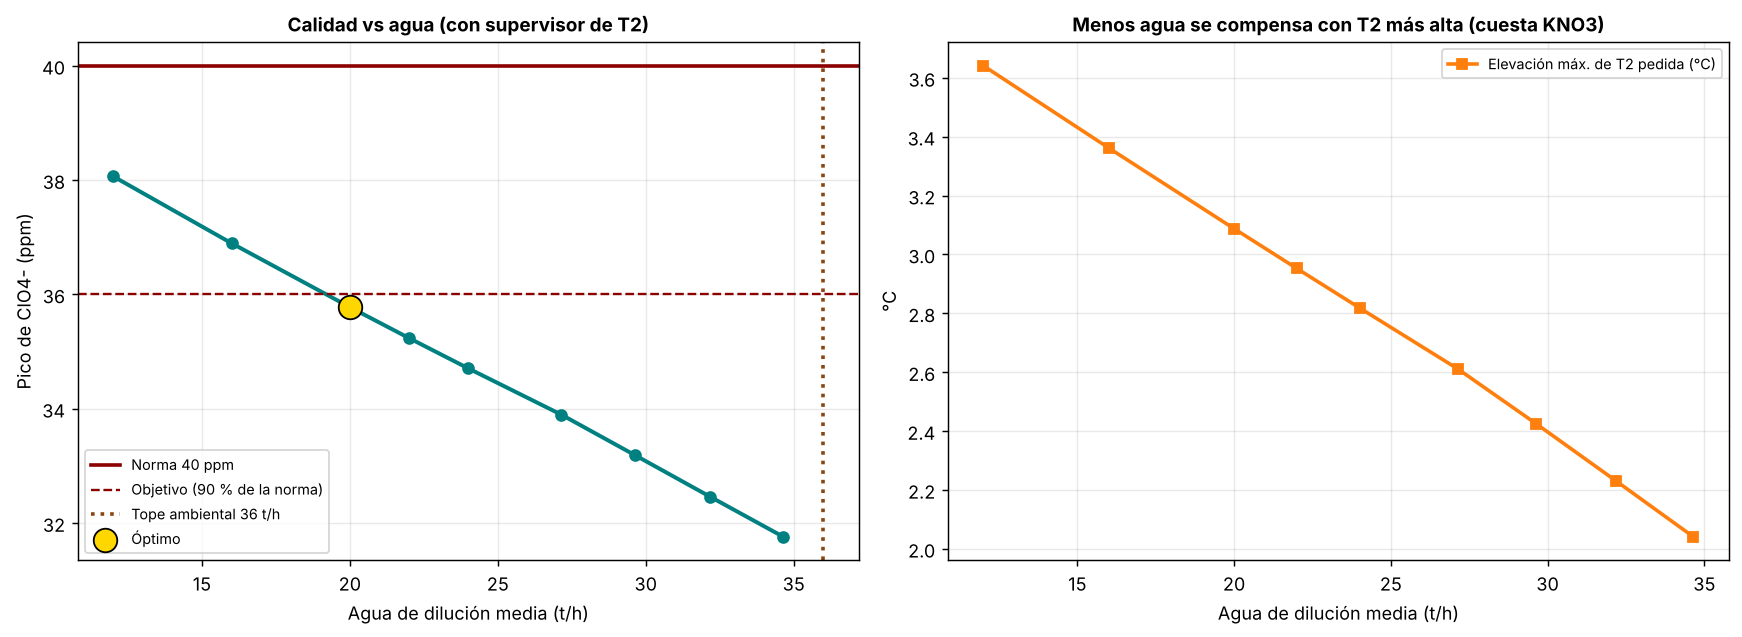

In [10]:
import sys, os, pathlib
_c = pathlib.Path.cwd()
_raiz = next((p for p in [_c, *_c.parents] if (p / "msmpr_core").is_dir()), None) or next(p for p in _c.glob("*") if (p / "msmpr_core").is_dir())
os.chdir(_raiz / "notebooks")          # rutas relativas ("../docs/fig") validas aunque VS Code abra el kernel en otra carpeta
if str(_raiz) not in sys.path:
    sys.path.insert(0, str(_raiz))
# %% [markdown]
# ## B7 · Agua mínima de dilución con tope ambiental
# El agua es un recurso escaso para la comunidad: el óptimo se busca como el **mínimo** que cumple la norma, y nunca por sobre el tope
# `plant.F303_MAX_AMBIENTAL` (36 t/h). Criterio (parametrizable en `plant.barrido_agua_optimo`): pico <= 90 % de la norma y pérdida de KNO3 <= 1 t/h
# respecto del mejor caso del barrido.

# %%
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from msmpr_core import plant as P

df_agua, opt = P.barrido_agua_optimo()
vista = df_agua[["tope_agua_t_h", "agua_media_t_h", "ppm_max", "KNO3_medio_t_h", "dT2_max_C", "perdida_KNO3_por_T_max_t_h", "factible"]].copy()
display(vista.round(2))
if opt:
    ahorro_vs_36 = (1 - opt["agua_media_t_h"] / 36.8) * 100
    print(f"ÓPTIMO: {opt['agua_media_t_h']:.1f} t/h de agua media (pico {opt['ppm_max']:.1f} ppm; KNO3 {opt['KNO3_medio_t_h']:.1f} t/h; "
          f"T2 sube hasta +{opt['dT2_max_C']:.1f} °C en las excursiones). Ahorro frente a 36.8 t/h: {ahorro_vs_36:.0f} %.")
else:
    print("Ningún tope del barrido cumple el criterio.")
fig, ax = plt.subplots(1, 2, figsize=(13.5, 5.0))
ax[0].plot(df_agua.agua_media_t_h, df_agua.ppm_max, "o-", color="teal", lw=2.2)
ax[0].axhline(P.PPM_NORMA, color="darkred", lw=2.0, label="Norma 40 ppm")
ax[0].axhline(0.9 * P.PPM_NORMA, color="darkred", ls="--", lw=1.3, label="Objetivo (90 % de la norma)")
ax[0].axvline(P.F303_MAX_AMBIENTAL, color="saddlebrown", ls=":", lw=2.0, label="Tope ambiental 36 t/h")
if opt:
    ax[0].scatter([opt["agua_media_t_h"]], [opt["ppm_max"]], color="gold", edgecolor="k", s=170, zorder=7, label="Óptimo")
ax[0].set_xlabel("Agua de dilución media (t/h)"); ax[0].set_ylabel("Pico de ClO4- (ppm)"); ax[0].legend(fontsize=8)
ax[0].set_title("Calidad vs agua (con supervisor de T2)")
ax[1].plot(df_agua.agua_media_t_h, df_agua.dT2_max_C, "s-", color="tab:orange", lw=2.0, label="Elevación máx. de T2 pedida (°C)")
ax[1].set_xlabel("Agua de dilución media (t/h)"); ax[1].set_ylabel("°C"); ax[1].legend(fontsize=8)
ax[1].set_title("Menos agua se compensa con T2 más alta (cuesta KNO3)")
fig.tight_layout()
fig.savefig("../docs/fig/PPT_Fig6_Optimo_Agua_con_Tope_Ambiental.png", bbox_inches="tight")
plt.show()


,ppm_max,T1_final_C,T2_final_C,vacio_A3110_saturado_pct,KNO3_medio_t_h,perdida_KNO3_por_T_final_t_h
Alimentacion +0 C (sin correccion),50.510645,55.0,40.0,0.0,63.91401,0.0
Alimentacion +5 C (sin correccion),50.510645,55.0,40.0,0.0,63.859565,0.0
Alimentacion +10 C (sin correccion),50.510645,55.219685,40.0,85.166667,63.474653,0.438726
Alimentacion +15 C (sin correccion),50.510645,57.469685,40.0,87.805556,59.742467,4.932133
+10 C con prealimentacion de vacio,50.510645,55.219685,40.0,88.333333,63.540359,0.438726
+10 C con agua de dilucion a 35 C,50.510645,55.0,40.0,0.0,63.81206,0.0
+10 C con agua a 35 C + prealimentacion,50.510645,55.0,40.0,0.0,63.911876,0.0
+10 C con prealimentacion + supervisor T2,31.757831,55.219685,42.040188,88.333333,61.333848,4.146427
Cristalizador 2 en 40 C,50.510645,55.0,40.0,0.0,63.91401,0.0
Cristalizador 2 en 42 C,31.757831,55.0,42.0,0.0,60.476515,3.634667


Carga térmica para enfriar el agua de dilución de 60 a 35 °C: 786 kW (rango de vacío A3110: 50.7-59.3 °C).


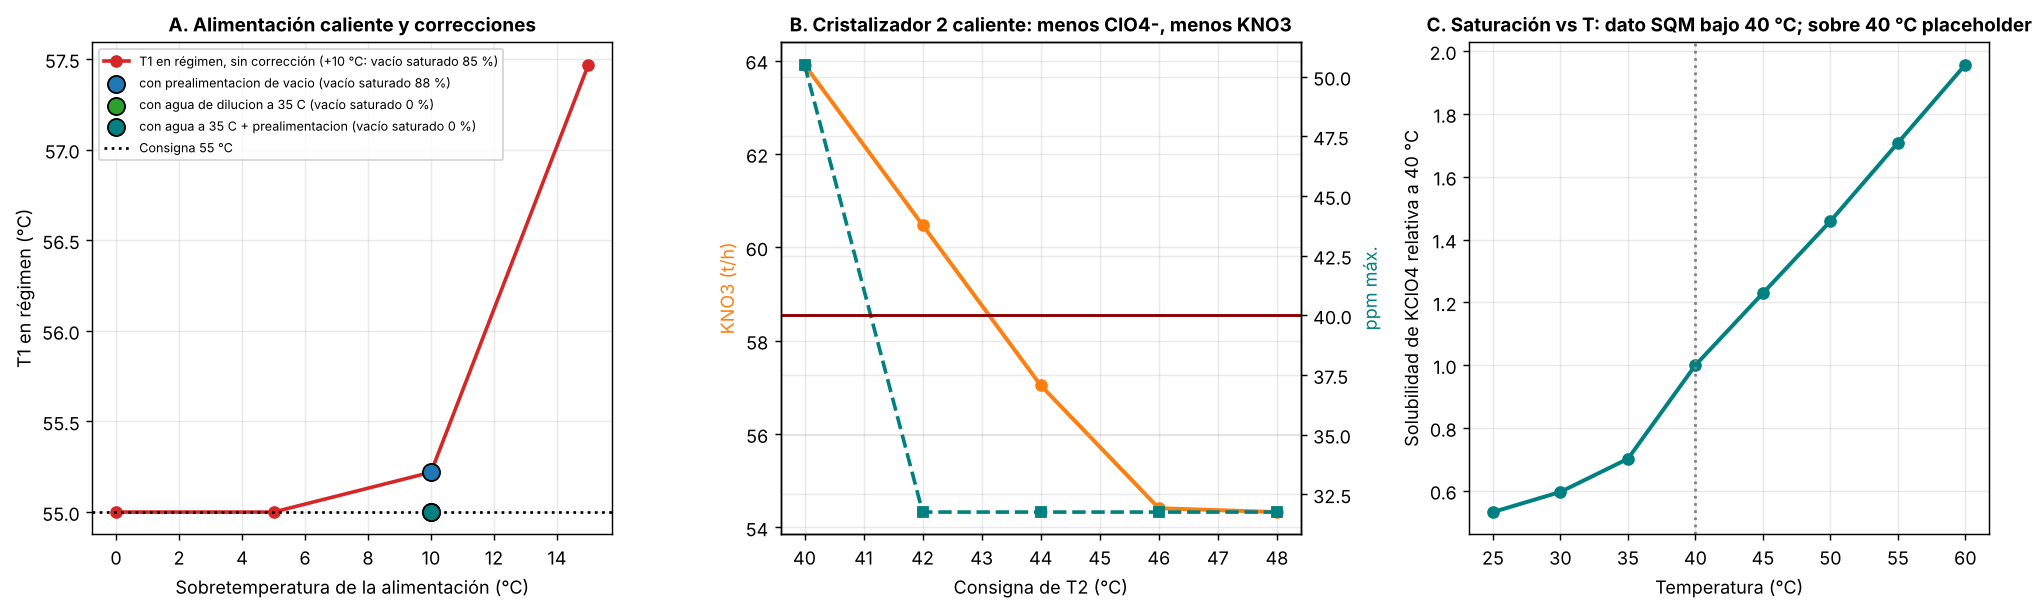

In [11]:
import sys, os, pathlib
_c = pathlib.Path.cwd()
_raiz = next((p for p in [_c, *_c.parents] if (p / "msmpr_core").is_dir()), None) or next(p for p in _c.glob("*") if (p / "msmpr_core").is_dir())
os.chdir(_raiz / "notebooks")          # rutas relativas ("../docs/fig") validas aunque VS Code abra el kernel en otra carpeta
if str(_raiz) not in sys.path:
    sys.path.insert(0, str(_raiz))
# %% [markdown]
# ## B8 · Temperatura: alimentación caliente antes de la dilución y cristalizadores operando calientes
# - La sobretemperatura de la alimentación previa a la dilución (+0.45 K por K en T1) y el agua de dilución a 60 °C empujan T1; el vacío de A3110 tiene rango limitado.
# - Un cristalizador caliente reduce el riesgo de precipitar KClO4 (mayor solubilidad) pero pierde KNO3 (~1.8 t/h por °C, Entrega 2, Tabla 8).
# - Sobre 40 °C la solubilidad de KClO4 en salmuera **no está medida**: se usa la razón del agua pura (placeholder; ver `plant.KCLO4_SOL_AGUA_REF`).

# %%
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from msmpr_core import plant as P

tabla_T = P.analisis_temperatura()
display(tabla_T[["ppm_max", "T1_final_C", "T2_final_C", "vacio_A3110_saturado_pct", "KNO3_medio_t_h", "perdida_KNO3_por_T_final_t_h"]].round(2))
print(f"Carga térmica para enfriar el agua de dilución de 60 a 35 °C: {P.calor_enfriar_agua_dilucion_kW():.0f} kW "
      f"(rango de vacío A3110: {P.vac_T(P.VAC['P1_lim'][0], 1):.1f}-{P.vac_T(P.VAC['P1_lim'][1], 1):.1f} °C).")

fig, ax = plt.subplots(1, 3, figsize=(15.5, 4.8))
alim = [n for n in tabla_T.index if n.startswith("Alimentacion +")]
ax[0].plot([float(n.split("+")[1].split()[0]) for n in alim], tabla_T.loc[alim, "T1_final_C"], "o-", color="tab:red", lw=2.0, label=f"T1 en régimen, sin corrección (+10 °C: vacío saturado {tabla_T.loc['Alimentacion +10 C (sin correccion)', 'vacio_A3110_saturado_pct']:.0f} %)")
corr = ["+10 C con prealimentacion de vacio", "+10 C con agua de dilucion a 35 C", "+10 C con agua a 35 C + prealimentacion"]
for n, c in zip(corr, ("tab:blue", "tab:green", "teal")):
    ax[0].scatter([10], [tabla_T.loc[n, "T1_final_C"]], s=90, color=c, edgecolor="k", label=n.replace("+10 C ", "") + f" (vacío saturado {tabla_T.loc[n, 'vacio_A3110_saturado_pct']:.0f} %)", zorder=5)
ax[0].axhline(55.0, color="k", ls=":", label="Consigna 55 °C")
ax[0].set_xlabel("Sobretemperatura de la alimentación (°C)"); ax[0].set_ylabel("T1 en régimen (°C)"); ax[0].legend(fontsize=7.0)
ax[0].set_title("A. Alimentación caliente y correcciones")
cal = [n for n in tabla_T.index if n.startswith("Cristalizador 2")]
T2v = [float(n.split(" en ")[1].split()[0]) for n in cal]
ax[1].plot(T2v, tabla_T.loc[cal, "KNO3_medio_t_h"], "o-", color="tab:orange", lw=2.2, label="KNO3 medio (t/h)")
ax[1].set_xlabel("Consigna de T2 (°C)"); ax[1].set_ylabel("KNO3 (t/h)", color="tab:orange")
axr = ax[1].twinx(); axr.plot(T2v, tabla_T.loc[cal, "ppm_max"], "s--", color="teal", lw=2.0, label="ClO4- máx. (ppm)")
axr.axhline(P.PPM_NORMA, color="darkred", lw=1.6); axr.set_ylabel("ppm máx.", color="teal")
ax[1].set_title("B. Cristalizador 2 caliente: menos ClO4-, menos KNO3")
Ts = [float(x) for x in range(25, 61, 5)]
ax[2].plot(Ts, [P.sat_factor_T(T) for T in Ts], "o-", color="teal", lw=2.2)
ax[2].axvline(40.0, color="gray", ls=":")
ax[2].set_xlabel("Temperatura (°C)"); ax[2].set_ylabel("Solubilidad de KClO4 relativa a 40 °C")
ax[2].set_title("C. Saturación vs T: dato SQM bajo 40 °C; sobre 40 °C placeholder")
fig.tight_layout()
fig.savefig("../docs/fig/PPT_Fig7_Analisis_Temperatura.png", bbox_inches="tight")
plt.show()


In [12]:
import sys, os, pathlib
_c = pathlib.Path.cwd()
_raiz = next((p for p in [_c, *_c.parents] if (p / "msmpr_core").is_dir()), None) or next(p for p in _c.glob("*") if (p / "msmpr_core").is_dir())
os.chdir(_raiz / "notebooks")          # rutas relativas ("../docs/fig") validas aunque VS Code abra el kernel en otra carpeta
if str(_raiz) not in sys.path:
    sys.path.insert(0, str(_raiz))
import pandas as pd
from msmpr_core import params as P
from msmpr_core.plant import Plant

rows = []
for prof in ("literatura", "calibracion", "planta_sqm"):
    p = P.make_params(prof)
    pl = Plant(p)
    x, u, d = pl.steady_state(alpha=0.25)
    m = pl.metrics(x, u, d)
    mg_in = p["feed_stock_kg_m3"]["Mg"]
    mg_licor = x[11] * (mg_in / d["S_stock"])
    rows.append({
        "Perfil": prof,
        "KNO3_in [kg/m3]": p["feed_stock_kg_m3"]["KNO3"],
        "Mg_in [kg/m3]": mg_in,
        "C*_40C [kg/m3]": round(p["Cstar_ref_kg_m3"], 2),
        "Recuperación Y [%]": round(m["recovery_pct"], 2),
        "Prod. KNO3 [t/h]": round(m["crystal_t_h"], 2),
        "d50 [µm]": round(m["d50_um"], 1),
        "Mg Licor [g/L]": round(mg_licor, 2),
        "ClO4 Prod [ppm]": round(m["ppm_ClO4"], 2),
        "Y_cierre": f"{m['Y_cierre']:.1e}",
    })

print(pd.DataFrame(rows).set_index("Perfil").to_string())

             KNO3_in [kg/m3]  Mg_in [kg/m3]  C*_40C [kg/m3]  Recuperación Y [%]  Prod. KNO3 [t/h]  d50 [µm]  Mg Licor [g/L]  ClO4 Prod [ppm]  Y_cierre
Perfil                                                                                                                                                
literatura           220.000        32.1115          180.00               10.98              6.44      87.4           31.14            35.72  -5.8e-16
calibracion          220.000        32.1115          180.00               10.48              6.15      86.5           30.96             0.04   1.7e-16
planta_sqm           525.228        32.1115          177.94               64.30             90.10     152.0           33.21            36.88   2.2e-15


,Corriente,Flujo (t/h),Mg Balance PFD (ppm),ClO4 Balance PFD (ppm),Mg Lab Media±DE,ClO4 Lab Media±DE
0,208 SSK (Entrada B2510),356.85,10206.0,3892.00,32.11 ± 4.34 g/L (AQ26: 28.68),3.80 ± 0.49 g/L (AQ26: 4.47)
1,234 ML Refinación (a B2510),21.33,2397.0,738.00,5.77 ± 2.41 g/L (med. 5.60),1.59 ± 1.01 g/L (med. 1.30)
2,303 Agua Dilución (FIRC 3103),27.14,329.0,36.00,0.33 g/L (MgCl2+MgSO4),0.036 g/L (KClO4: 50 ppm)
3,1 / 334 SSK-d (Entrada A3110),405.32,9134.0,3468.00,14.65 kg/m3 licor (wL=9654 ppm),5.56 kg/m3 licor (wL=3665 ppm)
4,11 / 368 Salida A3210 (40 °C),390.23,9376.0,3557.00,wL=11720 ppm (16.29 g/L),wL=4446 ppm (6.18 g/L)
5,MLK Purga / Recirculación B3520,223.67,10578.0,4012.00,31.03 ± 4.25 g/L (med. 31.0),3.59 ± 0.50 g/L (med. 3.60)
6,17 / 328 Queque Crudo (Área 3000),76.49,537.0,203.00,992 ± 425 ppm (med. 1000 ppm),314.7 ± 291.8 ppm (med. 202 ppm)
7,Producto Refinado (Área 6000),65.31,72.0,22.15,61.1 ± 28.6 ppm (med. 60 ppm),30.86 ± 19.19 ppm (med. 21 ppm)


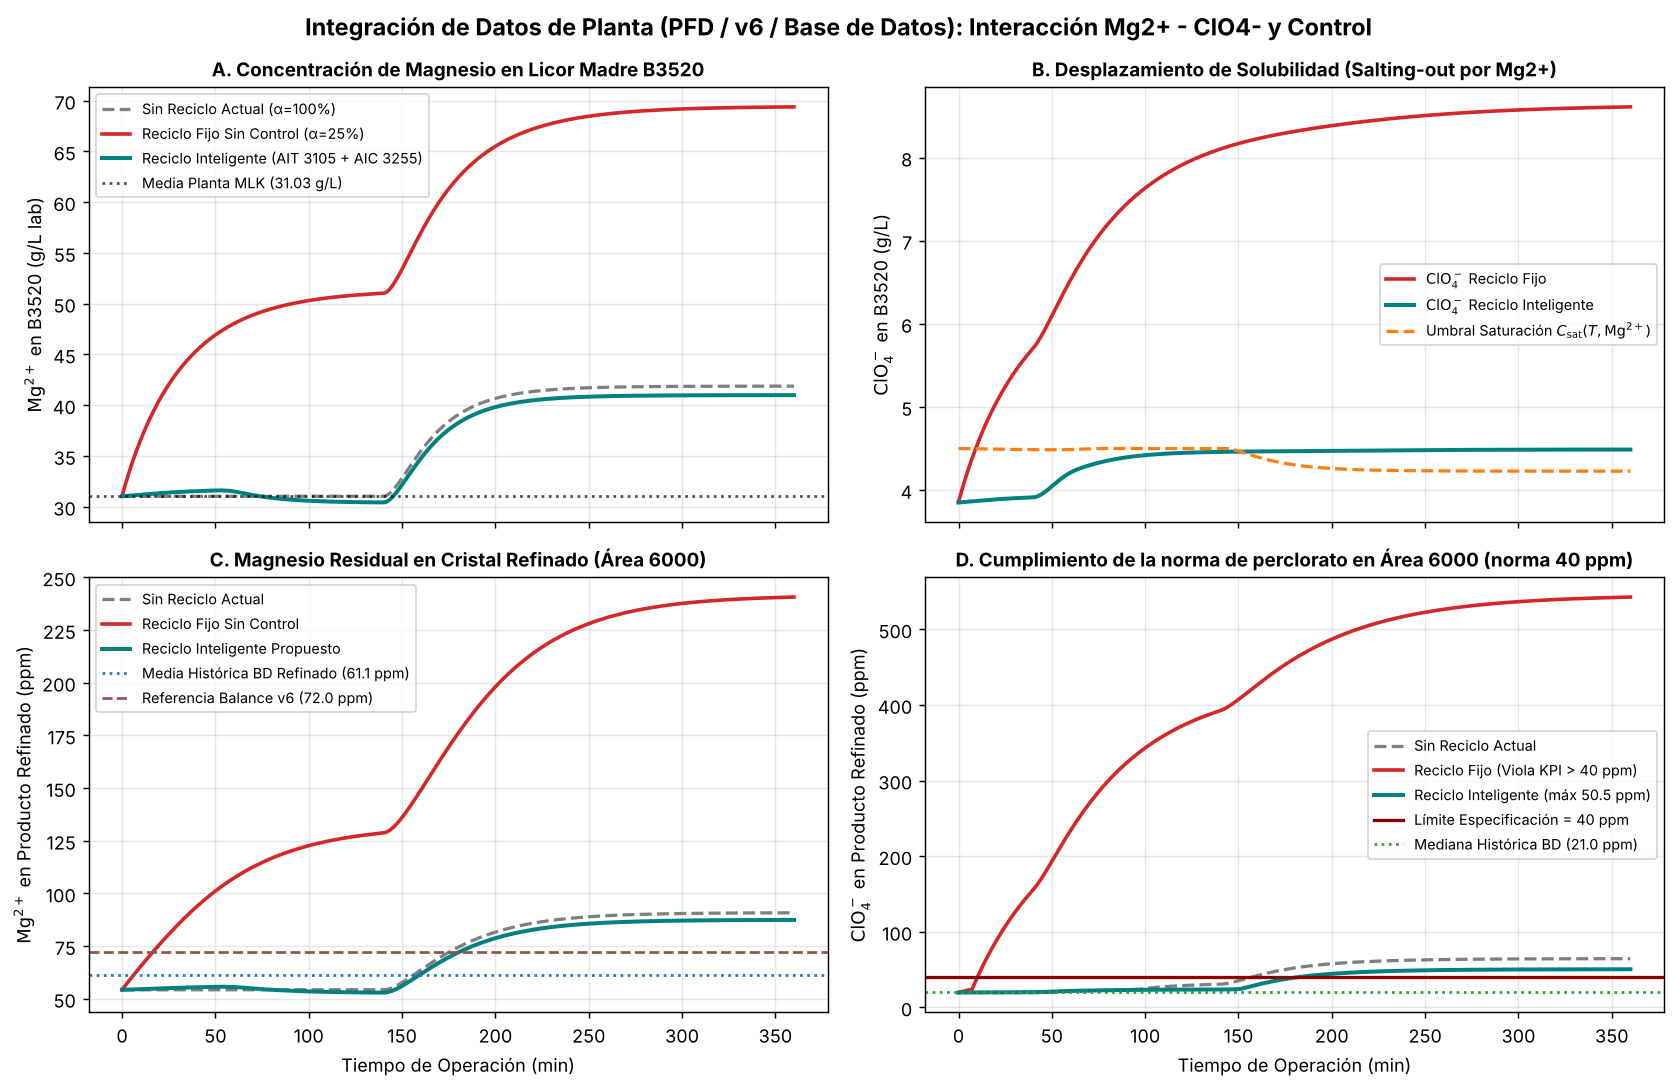

In [13]:
from IPython.display import display
import sys, os, pathlib
_c = pathlib.Path.cwd()
_raiz = next((p for p in [_c, *_c.parents] if (p / "msmpr_core").is_dir()), None) or next(p for p in _c.glob("*") if (p / "msmpr_core").is_dir())
os.chdir(_raiz / "notebooks")          # rutas relativas ("../docs/fig") validas aunque VS Code abra el kernel en otra carpeta
if str(_raiz) not in sys.path:
    sys.path.insert(0, str(_raiz))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from msmpr_core import plant as P

# 1. Resumen estadístico real desde Base de datos.xlsx y AQ SSKd.xlsx vs. Balance PFD/v6
tabla_conciliacion = pd.DataFrame([
    {"Corriente": "208 SSK (Entrada B2510)", "Flujo (t/h)": 356.85,
     "Mg Balance PFD (ppm)": 10206.0, "ClO4 Balance PFD (ppm)": 3892.0,
     "Mg Lab Media±DE": "32.11 ± 4.34 g/L (AQ26: 28.68)", "ClO4 Lab Media±DE": "3.80 ± 0.49 g/L (AQ26: 4.47)"},
    {"Corriente": "234 ML Refinación (a B2510)", "Flujo (t/h)": 21.33,
     "Mg Balance PFD (ppm)": 2397.0, "ClO4 Balance PFD (ppm)": 738.0,
     "Mg Lab Media±DE": "5.77 ± 2.41 g/L (med. 5.60)", "ClO4 Lab Media±DE": "1.59 ± 1.01 g/L (med. 1.30)"},
    {"Corriente": "303 Agua Dilución (FIRC 3103)", "Flujo (t/h)": 27.14,
     "Mg Balance PFD (ppm)": 329.0, "ClO4 Balance PFD (ppm)": 36.0,
     "Mg Lab Media±DE": "0.33 g/L (MgCl2+MgSO4)", "ClO4 Lab Media±DE": "0.036 g/L (KClO4: 50 ppm)"},
    {"Corriente": "1 / 334 SSK-d (Entrada A3110)", "Flujo (t/h)": 405.32,
     "Mg Balance PFD (ppm)": 9134.0, "ClO4 Balance PFD (ppm)": 3468.0,
     "Mg Lab Media±DE": "14.65 kg/m3 licor (wL=9654 ppm)", "ClO4 Lab Media±DE": "5.56 kg/m3 licor (wL=3665 ppm)"},
    {"Corriente": "11 / 368 Salida A3210 (40 °C)", "Flujo (t/h)": 390.23,
     "Mg Balance PFD (ppm)": 9376.0, "ClO4 Balance PFD (ppm)": 3557.0,
     "Mg Lab Media±DE": "wL=11720 ppm (16.29 g/L)", "ClO4 Lab Media±DE": "wL=4446 ppm (6.18 g/L)"},
    {"Corriente": "MLK Purga / Recirculación B3520", "Flujo (t/h)": 223.67,
     "Mg Balance PFD (ppm)": 10578.0, "ClO4 Balance PFD (ppm)": 4012.0,
     "Mg Lab Media±DE": "31.03 ± 4.25 g/L (med. 31.0)", "ClO4 Lab Media±DE": "3.59 ± 0.50 g/L (med. 3.60)"},
    {"Corriente": "17 / 328 Queque Crudo (Área 3000)", "Flujo (t/h)": 76.49,
     "Mg Balance PFD (ppm)": 537.0, "ClO4 Balance PFD (ppm)": 203.0,
     "Mg Lab Media±DE": "992 ± 425 ppm (med. 1000 ppm)", "ClO4 Lab Media±DE": "314.7 ± 291.8 ppm (med. 202 ppm)"},
    {"Corriente": "Producto Refinado (Área 6000)", "Flujo (t/h)": 65.31,
     "Mg Balance PFD (ppm)": 72.0, "ClO4 Balance PFD (ppm)": 22.15,
     "Mg Lab Media±DE": "61.1 ± 28.6 ppm (med. 60 ppm)", "ClO4 Lab Media±DE": "30.86 ± 19.19 ppm (med. 21 ppm)"},
])
display(tabla_conciliacion)

# 2. Simulación comparativa de los 3 modos de operación con datos conciliados de Mg2+ y ClO4-
df_sin_rec = P.simular_recirculacion_y_magnesio("sin_reciclo_actual", use_AIT3105=False, hipotesis_mg="combinada")
df_rec_fijo = P.simular_recirculacion_y_magnesio("reciclo_fijo", use_AIT3105=False, hipotesis_mg="combinada")
df_rec_smart = P.simular_recirculacion_y_magnesio("reciclo_inteligente", use_AIT3105=True, hipotesis_mg="combinada")

fig, ax = plt.subplots(2, 2, figsize=(13, 8.5), sharex=True)
fig.suptitle("Integración de Datos de Planta (PFD / v6 / Base de Datos): Interacción Mg2+ - ClO4- y Control", fontsize=13, fontweight="bold")

# Panel A: Magnesio en B3520 (g/L escala laboratorio BD)
ax[0, 0].plot(df_sin_rec["t_min"], df_sin_rec["C_Mg_B3520_g_L"], "--", color="tab:gray", lw=1.8, label="Sin Reciclo Actual (α=100%)")
ax[0, 0].plot(df_rec_fijo["t_min"], df_rec_fijo["C_Mg_B3520_g_L"], "-", color="tab:red", lw=2.0, label="Reciclo Fijo Sin Control (α=25%)")
ax[0, 0].plot(df_rec_smart["t_min"], df_rec_smart["C_Mg_B3520_g_L"], "-", color="teal", lw=2.2, label="Reciclo Inteligente (AIT 3105 + AIC 3255)")
ax[0, 0].axhline(31.03, color="black", ls=":", alpha=0.7, label="Media Planta MLK (31.03 g/L)")
ax[0, 0].set_ylabel(r"$\mathrm{Mg^{2+}}$ en B3520 (g/L lab)")
ax[0, 0].set_title("A. Concentración de Magnesio en Licor Madre B3520")
ax[0, 0].legend(fontsize=8)
ax[0, 0].grid(True, alpha=0.3)

# Panel B: Perclorato en B3520 vs Umbral de Salting-out por Mg2+
ax[0, 1].plot(df_rec_fijo["t_min"], df_rec_fijo["C_ClO4_B3520_g_L"], "-", color="tab:red", lw=2.0, label=r"$\mathrm{ClO_4^-}$ Reciclo Fijo")
ax[0, 1].plot(df_rec_smart["t_min"], df_rec_smart["C_ClO4_B3520_g_L"], "-", color="teal", lw=2.2, label=r"$\mathrm{ClO_4^-}$ Reciclo Inteligente")
ax[0, 1].plot(df_rec_smart["t_min"], df_rec_smart["C_sat_eff"], "--", color="tab:orange", lw=1.8, label=r"Umbral Saturación $C_{\mathrm{sat}}(T, \mathrm{Mg^{2+}})$")
ax[0, 1].set_ylabel(r"$\mathrm{ClO_4^-}$ en B3520 (g/L)")
ax[0, 1].set_title("B. Desplazamiento de Solubilidad (Salting-out por Mg2+)")
ax[0, 1].legend(fontsize=8)
ax[0, 1].grid(True, alpha=0.3)

# Panel C: Magnesio residual en Producto Refinado Área 6000 (ppm)
ax[1, 0].plot(df_sin_rec["t_min"], df_sin_rec["ppm_Mg_final_6000"], "--", color="tab:gray", lw=1.8, label="Sin Reciclo Actual")
ax[1, 0].plot(df_rec_fijo["t_min"], df_rec_fijo["ppm_Mg_final_6000"], "-", color="tab:red", lw=2.0, label="Reciclo Fijo Sin Control")
ax[1, 0].plot(df_rec_smart["t_min"], df_rec_smart["ppm_Mg_final_6000"], "-", color="teal", lw=2.2, label="Reciclo Inteligente Propuesto")
ax[1, 0].axhline(61.1, color="tab:blue", ls=":", label="Media Histórica BD Refinado (61.1 ppm)")
ax[1, 0].axhline(72.0, color="tab:brown", ls="--", label="Referencia Balance v6 (72.0 ppm)")
ax[1, 0].set_xlabel("Tiempo de Operación (min)")
ax[1, 0].set_ylabel(r"$\mathrm{Mg^{2+}}$ en Producto Refinado (ppm)")
ax[1, 0].set_title("C. Magnesio Residual en Cristal Refinado (Área 6000)")
ax[1, 0].legend(fontsize=8)
ax[1, 0].grid(True, alpha=0.3)

# Panel D: Perclorato en Producto Refinado Final Área 6000 vs KPI < 40 ppm
ax[1, 1].plot(df_sin_rec["t_min"], df_sin_rec["ppm_ClO4_final_6000"], "--", color="tab:gray", lw=1.8, label="Sin Reciclo Actual")
ax[1, 1].plot(df_rec_fijo["t_min"], df_rec_fijo["ppm_ClO4_final_6000"], "-", color="tab:red", lw=2.0, label="Reciclo Fijo (Viola KPI > 40 ppm)")
ax[1, 1].plot(df_rec_smart["t_min"], df_rec_smart["ppm_ClO4_final_6000"], "-", color="teal", lw=2.2, label=f"Reciclo Inteligente (máx {df_rec_smart['ppm_ClO4_final_6000'].max():.1f} ppm)")
ax[1, 1].axhline(40.0, color="darkred", lw=1.8, label="Límite Especificación = 40 ppm")
ax[1, 1].axhline(21.0, color="tab:green", ls=":", label="Mediana Histórica BD (21.0 ppm)")
ax[1, 1].set_xlabel("Tiempo de Operación (min)")
ax[1, 1].set_ylabel(r"$\mathrm{ClO_4^-}$ en Producto Refinado (ppm)")
ax[1, 1].set_title("D. Cumplimiento de la norma de perclorato en Área 6000 (norma 40 ppm)")
ax[1, 1].legend(fontsize=8)
ax[1, 1].grid(True, alpha=0.3)

fig.tight_layout()
plt.show()
